# M09a · Matrices et systèmes linéaires — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m09a_matrices/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M09a.1 à M09a.14, M09a.19, M09a.20 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M09a.25 | Le produit matriciel et la transposée · `matmul, transpose` | 🔨 | ★ | 20 |
|  | M09a.26 | La forme échelonnée réduite et le rang · `rref, rank` | 🔨 | ★★ | 35 |
|  | M09a.27 | Résoudre un système par le pivot de Gauss · `solve` | 🔨 | ★★ | 30 |
|  | M09a.28 | L'inverse par Gauss-Jordan · `inverse` | 🔨 | ★ | 20 |
|  | M09a.29 | `@`, `*`, `.T`, `np.linalg.solve`, `matrix_rank` et `sympy.Matrix.rref` contre tes fonctions | 📦 | ★ | 15 |
| B | M09a.30 | Prédire la forme du résultat : `@`, `*` et broadcasting | 🔮 | ★ | 10 |
|  | M09a.31 | Le temps d'un produit matriciel en fonction de n : une pente de 3 en échelle log-log | 🔬 | ★★ | 20 |
|  | M09a.32 | Pourquoi le pivot partiel : un petit pivot et les arrondis | 🔬 | ★★ | 20 |
|  | M09a.33 | Une matrice 2 × 2 comme transformation du plan : la grille et le carré unité | 🎨 | ★ | 20 |
| C | M09a.34 | Chasse à l'erreur : `*` au lieu de `@`, une transposée oubliée, un pivot nul | 🐛 | ★ | 15 |
|  | M09a.35 | Tester une propriété : un pytest pour (AB)ᵀ = BᵀAᵀ sur des matrices aléatoires | 🛠️ | ★ | 15 |
|  | M09a.36 | Défi : un système 500 × 500 résolu par ton `solve`, à 1e−8 près de NumPy, en moins d'une seconde | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : formes et moyennes d'un tableau, produits matrice-vecteur et matriciels, coût des parenthèses, couche dense, embedding, transposées et $\mathbf{X}^\top\mathbf{X}$, pivot de Gauss, formes réduites, inverses, rangs, un problème mis en système, passe avant, standardisation.
- Écrire les six fonctions de `mymath/matrices.py` et les tester, puis comparer avec NumPy et SymPy.
- Prédire des formes, mesurer le coût $n^3$ et l'effet du pivot partiel, voir une matrice comme une transformation du plan, chasser des erreurs, tester une propriété, résoudre un grand système.

**Rappel express.** $(n, p) \times (p, m) \to (n, m)$ ; $(\mathbf{A}\mathbf{B})_{ij} = \sum_k a_{ik}b_{kj}$, $n\,p\,m$ multiplications ; $\mathbf{A}\mathbf{x} = \sum_j x_j\mathbf{a}_j$ ; $\mathbf{Z} = \mathbf{X}\mathbf{W} + \mathbf{b}$ ; $(\mathbf{A}\mathbf{B})^\top = \mathbf{B}^\top\mathbf{A}^\top$ ; opérations élémentaires : échanger, multiplier par $\lambda \ne 0$, ajouter un multiple d'une autre ligne ; $\mathbf{A}\mathbf{A}^{-1} = \mathbf{I}$, $\begin{pmatrix} a & b \\ c & d \end{pmatrix}^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}$ ; rang = nombre de pivots.

## Partie 0 · Vérifier tes exercices papier (✏️ M09a.1 à M09a.14, 🔗 M09a.19 et M09a.20)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ;
- une liste `[2, -1, 0]` pour un vecteur ou une forme, une liste de lignes `[[1, 0], [-2, 3]]` pour une matrice, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import numpy as np

X1 = np.array([[22, 60, 12], [25, 55, 18], [19, 70, 8], [24, 65, 15], [20, 50, 7]], dtype=float)     # M09a.1
A2 = np.array([[3, -1, 2, 0], [1, 4, -2, 5], [-2, 0, 1, 3]])                                        # M09a.2
X2 = np.array([2, -1, 3, 1])
XG2, WG2 = np.array([[2, 1, 0], [-1, 3, 2]]), np.array([0.5, -1, 2])
A3 = np.array([[1, -1, 2], [0, 3, 1]])                                                              # M09a.3
B3 = np.array([[2, 1], [-1, 0], [1, 4]])
C3 = np.array([[1, 2], [-1, 1]])
X5 = np.array([[1, 0, 2], [-1, 3, 1]])                                                              # M09a.5
W5 = np.array([[2, -1], [0, 1], [1, 3]])
B5 = np.array([-1, 0.5])
E6 = np.array([[0.1, -0.4, 1.2], [0.9, 0.0, -0.3], [-1.1, 0.6, 0.2], [0.5, 1.5, -0.8], [0.0, -0.2, 0.7]])  # M09a.6
A7 = np.array([[2, 0], [1, -1], [-1, 3]])                                                           # M09a.7
B7 = np.array([[1, 4, 0], [2, -1, 1]])
X7 = np.array([[1, -1, 2], [0, 2, 1], [2, 1, 0], [1, 0, -1]])
W19, B19 = np.array([[1, 0, 2], [-1, 1, 1]]), np.array([0, 0.5, -1])                               # M09a.19
V19 = np.array([1, 2, -1])
H19 = np.maximum(np.array([1, -1]) @ W19 + B19, 0)
X20 = np.array([[2, 10], [4, 30], [6, 20]], dtype=float)                                            # M09a.20

**Ex M09a.1 — Un tableau de données vu comme une matrice : forme, lignes, colonnes, moyennes**

In [3]:
wbm.record("M09a.1a", [5, 3], mistakes={"la forme s'écrit (lignes, colonnes), dans cet ordre": [3, 5]})
wbm.record("M09a.1b", 70, mistakes={"x_32 est à la ligne 3 et à la colonne 2 : la ligne d'abord": 18})
wbm.record("M09a.1c", [2, 1], mistakes={"en Python, les indices commencent à 0 : retire 1 à chaque indice mathématique": [3, 2], "la ligne d'abord, puis la colonne": [1, 2]})
wbm.record("M09a.1d", [24, 65, 15], mistakes={"les lignes sont numérotées à partir de 1 : la ligne 4 est la quatrième": [20, 50, 7]})
wbm.record("M09a.1e", X1.mean(axis=0), decimals=1, mistakes={"une moyenne par colonne (axis=0), pas par ligne": X1.mean(axis=1)})
wbm.record("M09a.1f", X1[1] - X1.mean(axis=0), decimals=1, mistakes={"centrer retire la moyenne de chaque colonne, pas l'inverse": X1.mean(axis=0) - X1[1]})
wbm.record("M09a.1g", X1[:, 0].std(), decimals=4, mistakes={"ddof = 0 : divise la somme des carrés des écarts par n = 5": X1[:, 0].std(ddof=1), "l'écart-type est la racine de la variance": X1[:, 0].var()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["38aaf607865f23d8c9d1018c2b3fc7f17e4f322de007f9b65144f651be0988f2", "0011139ea662ecf353053770c7eb65f50ee3b8ddd287607b6ad1e1d0f9d9c9a0"], "hash": "19111d978f0e8e54a9b25f57c7bf953abebc4cd05938ddff4a69972115c4aa01", "id": "M09a.1a", "integer": true, "kind": "array", "mistakes": {"ed65186dc13edb818f87e0ff50ec8db9d2c92bfccfefa35f80c8e43cd81a6545": "la forme s'écrit (lignes, colonnes), dans cet ordre"}, "shape": [2]}
📝 Ex M09a.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "6b92da2e37f330b89f22c697c8f213748d33e2754b1383420d4d3f4fdbf61991", "id": "M09a.1b", "kind": "int", "magnitude": 1, "mistakes": {"f29626e3ccb92a099b9bef52dcd3f6fd368fee8e84ca8b2eefbbfe2c27a3e5cd": "x_32 est à la ligne 3 et à la colonne 2 : la ligne d'abord"}, "sign": 1}
📝 Ex M09a.1b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["60af734db80f39b2adaec0c04c6f153cb4cc90c393b237b1354297a771ca3cd4", "3fa354f2c1bb1f2ca0d43296e7c43e17fe9

**Ex M09a.2 — Le produit matrice-vecteur, par les lignes puis par les colonnes**

In [4]:
wbm.record("M09a.2a", 3, mistakes={"Ax a autant de coordonnées que A a de lignes": 4})
wbm.record("M09a.2b", (A2 @ X2).tolist(), mistakes={"la coordonnée i est le produit scalaire de la ligne i de A avec x, en respectant les signes": (np.abs(A2) @ np.abs(X2)).tolist()})
wbm.record("M09a.2c", 12, mistakes={"chaque coordonnée de Ax demande une multiplication par élément de sa ligne de A": 7})
wbm.record("M09a.2d", A2[:, 2].tolist(), mistakes={"A e_3 sélectionne la colonne 3 de A, pas sa ligne 3": [-2, 0, 1, 3], "e_3 a son 1 en position 3, en comptant à partir de 1": [0, 5, 3]})
wbm.record("M09a.2e", [1, 0, 0, 2], mistakes={"Ay = y₁a₁ + … + y₄a₄ : y_j est le coefficient de la colonne j": [2, 0, 0, 1]})
wbm.record("M09a.2f", False, mistakes={"A a 4 colonnes : le vecteur doit avoir 4 coordonnées": True})
wbm.record("M09a.2g", (XG2 @ WG2 + 1).tolist(), decimals=1, mistakes={"le biais b = 1 s'ajoute à chaque prédiction": (XG2 @ WG2).tolist()})

WBM_ANSWER {"hash": "b0d5b869b77bffa368d0121d01b32068e3b26201c843cc9254d500ef08db09d1", "id": "M09a.2a", "kind": "int", "magnitude": 0, "mistakes": {"eb60942b43007b4ec654a5cf51e0f9bb84972635f44cb320c9200768585d60db": "Ax a autant de coordonnées que A a de lignes"}, "sign": 1}
📝 Ex M09a.2a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["6b2b3564e81cea444bef768653e774562a8fe14964794c553a9ed017a9a28edf", "f3917ed77a4f061e78d2e1421004d3219dcf4f72414f56cbb16269daf9ac9f97", "52eef7dd8a28975e5774eb226a63485055a6351775691040d0ee20f96e43ca14"], "hash": "2ae145d121dffb2d7060754f19b30926f474160453545a6d01d8dc5bffd66ffd", "id": "M09a.2b", "integer": true, "kind": "array", "mistakes": {"1ba96e221ddc7402fed644b1066482aa99e53f26f31a94b76aab3c48937493f0": "la coordonnée i est le produit scalaire de la ligne i de A avec x, en respectant les signes"}, "shape": [3]}
📝 Ex M09a.2b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "b6559a4066ecc3a4f8ff511e3228a30064a

**Ex M09a.3 — Produits matriciels à la main : formes compatibles et calculs**

In [5]:
wbm.record("M09a.3a", [2, 2])
wbm.record("M09a.3b", (A3 @ B3).tolist(), mistakes={"le produit n'est pas commutatif : garde l'ordre des matrices de l'énoncé : AB, pas BA": (B3 @ A3).tolist()})
wbm.record("M09a.3c", [3, 3])
wbm.record("M09a.3d", int((B3 @ A3)[1, 2]), mistakes={"(BA)_23 : la ligne 2 de B avec la colonne 3 de A": int((B3 @ A3)[2, 1])})
wbm.record("M09a.3e", False, mistakes={"A a 3 colonnes et C a 2 lignes : les dimensions intérieures diffèrent": True})
wbm.record("M09a.3f", (C3 @ A3).tolist())
wbm.record("M09a.3g", (A3 @ B3 @ C3).tolist(), mistakes={"le produit n'est pas commutatif : garde l'ordre des matrices de l'énoncé : (AB)C, avec C à droite": (C3 @ A3 @ B3).tolist()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a6ea55b5e15f137ad03c7b4efeef9be210d0b806a4ae858affaea26ef1d83f44", "146d51d1652289cf4d558c5b684fd379195567c4e8f03ec115a49a1571460fa8"], "hash": "08090edc762ff89cd9ebb98ff677553e3f44dc2ddb6003558d8a312814980ec6", "id": "M09a.3a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M09a.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["62b2b0aab59b3540cf4d742f430145cd7ae9e2d1da42d3070234979b23abebd2", "15249884c9a0979d448a09321bd540f9e3c6e36a66904ed922cfbb9416fe9759", "831b8a9feedb852943e2bc9a8397baea495b2e4483c56695ef344a3f2ae44143", "d59d27b34b168fc8f3cf45b0e500d0ea2ec250fac589d1017600e071ddc3b698"], "hash": "6db90f9c2d814d3ef52867e727a285f5525530d5fdfa5cc0af6e41d9602ef315", "id": "M09a.3b", "integer": true, "kind": "array", "mistakes": {"a16a7e3e9e80877b145fcedd627939cdc7f58ee874b3808687493b7c3c3fd079": "le produit n'est pas commutatif : garde l'ordre des matrices de l'énoncé : AB, pas BA"}, "sh

**Ex M09a.4 — Le coût d'un produit, et l'ordre des parenthèses dans ABC**

In [6]:
wbm.record("M09a.4a", 20 * 400 * 5, mistakes={"un produit (n, p) × (p, m) coûte n p m multiplications : les trois dimensions": 20 * 5})
wbm.record("M09a.4b", 20 * 400 * 5 + 20 * 5 * 300, mistakes={"le second produit, (AB)C, coûte aussi : (20, 5) × (5, 300)": 20 * 400 * 5})
wbm.record("M09a.4c", 400 * 5 * 300 + 20 * 400 * 300, mistakes={"le second produit est A fois BC, de forme (400, 300) : (20, 400) × (400, 300)": 400 * 5 * 300})
wbm.record("M09a.4d", (400 * 5 * 300 + 20 * 400 * 300) / (20 * 400 * 5 + 20 * 5 * 300), decimals=1, mistakes={"le rapport est le coût de A(BC) divisé par celui de (AB)C": (20 * 400 * 5 + 20 * 5 * 300) / (400 * 5 * 300 + 20 * 400 * 300), "le rapport des deux coûts, pas le surcoût relatif (rapport − 1)": (400 * 5 * 300 + 20 * 400 * 300) / (20 * 400 * 5 + 20 * 5 * 300) - 1})
wbm.record("M09a.4e", [20, 300])
wbm.record("M09a.4f", 5 * 300 * 2 + 400 * 5 * 2 + 20 * 400 * 2, mistakes={"de gauche à droite n'est pas le meilleur ordre ici : compare les ordres possibles": 20 * 400 * 5 + 20 * 5 * 300 + 20 * 300 * 2, "(AB)(CD) n'est pas le meilleur ordre : essaie de commencer par la droite": 20 * 400 * 5 + 5 * 300 * 2 + 20 * 5 * 2})
wbm.record("M09a.4g", 27, mistakes={"le coût d'un produit carré varie comme n³": {3, 9}})

WBM_ANSWER {"hash": "dc11fb2e851a59e6a2e620e4371d4ba2084e21a9f2e678f18fe0197ee767fc7a", "id": "M09a.4a", "kind": "int", "magnitude": 4, "mistakes": {"38369dc4b355c7f20a84ace7f8dd5b4979cd822f2b9c7305b2e2198c20ddf5ba": "un produit (n, p) × (p, m) coûte n p m multiplications : les trois dimensions"}, "sign": 1}
📝 Ex M09a.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "6b129000643d10dd9c683eb0f8f71aa8bf9b63b96df781ec361d0b39efae2fa4", "id": "M09a.4b", "kind": "int", "magnitude": 4, "mistakes": {"59fa75626e929ac1089451ff30db5c0bd660b89df8c8ccee27464e2d0d6eb557": "le second produit, (AB)C, coûte aussi : (20, 5) × (5, 300)"}, "sign": 1}
📝 Ex M09a.4b : réponse enregistrée (int).
WBM_ANSWER {"hash": "af1709b3538e28214e8c223cf07de3bdda7f69f9b9dd6769e581d4f9d427360c", "id": "M09a.4c", "kind": "int", "magnitude": 6, "mistakes": {"dfa6bc2d2dd0becdd701b1bf40b3e7bb7f42a85459f4e265a9530ce31daf0334": "le second produit est A fois BC, de forme (400, 300) : (20, 400) × (400, 300)"}, "sign": 1}
📝 Ex 

**Ex M09a.5 — Une couche dense Z = XW + b à la main : deux exemples, trois entrées, deux sorties**

In [7]:
wbm.record("M09a.5a", [3, 2], mistakes={"la forme s'écrit (lignes, colonnes), dans cet ordre : 3 entrées, 2 neurones": [2, 3]})
wbm.record("M09a.5b", (X5 @ W5 + B5).tolist(), decimals=1, mistakes={"le biais b s'ajoute à chaque ligne de XW": (X5 @ W5).tolist(), "le biais b_j s'ajoute à la colonne j (le neurone j), sur chaque ligne": (X5 @ W5 + B5[::-1]).tolist()})
wbm.record("M09a.5c", float((X5 @ W5 + B5)[1, 0]), decimals=1, mistakes={"z_21 : ligne 2 (l'exemple 2), colonne 1 (le neurone 1)": float((X5 @ W5 + B5)[0, 1])})
wbm.record("M09a.5d", np.maximum(X5 @ W5 + B5, 0).tolist(), decimals=1, mistakes={"ReLU met à zéro les nombres négatifs et garde les autres": np.abs(X5 @ W5 + B5).tolist()})
wbm.record("M09a.5e", 8, mistakes={"compte aussi les biais, un par neurone": 6})
wbm.record("M09a.5f", [2, 3], mistakes={"PyTorch range les poids de nn.Linear en (n_out, n_in)": [3, 2]})
wbm.record("M09a.5g", 12, mistakes={"un produit (n, p) × (p, m) coûte n p m multiplications": 6})

WBM_ANSWER {"decimals": 0, "element_hashes": ["fd8a63043ea746a892a03d9eb3719526c7220b8cc3719e94d9cadaf524af6bf8", "067090353f65e0cbeac384c885e405e7cbc393cff6ad1e308d9c72d09567230c"], "hash": "3eee293340f9393a5394d3982ec523ec8b24060cbfa997f594c6b870d1cb5fab", "id": "M09a.5a", "integer": true, "kind": "array", "mistakes": {"0758d1312cc71b1dc1ede9031de7d6bf42e02a0c1805b8a4ef475a938e02b2e7": "la forme s'écrit (lignes, colonnes), dans cet ordre : 3 entrées, 2 neurones"}, "shape": [2]}
📝 Ex M09a.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 1, "element_hashes": ["de8a2e39416dbc5e9a3410ccb0e954f01739e7490fc01e4c9cf6b8c11c01bc5a", "1ca1f1e23064ec7a5d31a9c5ae82ee2e4435ee3c71b04fc09f06f7fa98ee5471", "d631c193afe86951e9a060aa8eb7aba4e3215a33401756f534ee999f932dec19", "0c06b9cace85849c6ed15119c56e75fafb593027be9a6921a2c4fcb05cdb3882"], "hash": "de112e24ccd92542ae9ff3edfb09a9ca621ed8c9c4e25a22a3f70447028f0cc1", "id": "M09a.5b", "kind": "array", "mistakes": {"14cbfdbc1164d276

**Ex M09a.6 — Un embedding : une ligne one-hot fois une matrice**

In [8]:
wbm.record("M09a.6a", [0, 0, 0, 1, 0], mistakes={"le mot 4 a son 1 à la quatrième place (en comptant à partir de 1)": [0, 0, 0, 0, 1]})
wbm.record("M09a.6b", E6[3].tolist(), decimals=1, mistakes={"les lignes de E sont numérotées à partir de 1, comme les mots": E6[2].tolist()})
wbm.record("M09a.6c", 15)
wbm.record("M09a.6d", 15, mistakes={"sans raccourci, chaque élément de E est multiplié une fois": 3})
wbm.record("M09a.6e", (E6[1] + E6[4]).tolist(), decimals=1, mistakes={"un 1 en position j sélectionne la ligne j de E, en comptant à partir de 1": (E6[0] + E6[3]).tolist()})
wbm.record("M09a.6f", ((E6[0] + 2 * E6[2]) / 3).tolist(), decimals=4, mistakes={"le mot 3 compte deux fois : le coefficient 2": ((E6[0] + E6[2]) / 3).tolist(), "divise la somme par 3, le nombre de mots": (E6[0] + 2 * E6[2]).tolist()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["e56aa31b38aea1f0d5f84724aadf5322e27b1478b3b89901efaa723b5cc95d22", "07ff033e98855cd4ae43c374b7503640f32dd67df1c1a564f2f66249c49284bb", "b6b435e539e9a13093eb78dc1dadba21b26ded13a7876b61a1e8f9dbec849a48", "f5e99567982200683cfee90143b489c7874a04037b3cfb2255a8ec45f5e63eed", "855a607350c26684891ab14df9f988f6b9a35e182929233c36a494f5677be964"], "hash": "75893cf26491140e5cbc1ead408130d72cd792201a406e633378f83bdc61e199", "id": "M09a.6a", "integer": true, "kind": "array", "mistakes": {"3ce54c10ef301dcd5982ef9d36a4c9f97a34c6ec2c3ad597c0a973e700d961c0": "le mot 4 a son 1 à la quatrième place (en comptant à partir de 1)"}, "shape": [5]}
📝 Ex M09a.6a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 1, "element_hashes": ["eaa92b23876ef3acd8bc994cb6d5ca33dbd4ffa59ae1152179c5b10b1f095869", "a40bb6033aa3216c6854c2cf2f6aa3194b7be1c9d94cad5f4c86b2a33441c9d5", "c3cea0ca7a5e56d55746a1595df113f6d212d74c7faba5ef7a50974599ef62aa"], "hash": "baae7

**Ex M09a.7 — Transposées de produits, et la matrice symétrique XᵀX**

In [9]:
wbm.record("M09a.7a", [3, 3])
wbm.record("M09a.7b", (A7 @ B7).T.tolist(), mistakes={"la transposée échange lignes et colonnes : ce résultat est AB lui-même": (A7 @ B7).tolist()})
wbm.record("M09a.7c", (B7 @ A7).T.tolist(), mistakes={"la transposée échange lignes et colonnes : ce résultat est BA lui-même": (B7 @ A7).tolist()})
wbm.record("M09a.7d", False, mistakes={"compare les formes : AᵀBᵀ est (2, 3) × (3, 2)": True})
wbm.record("M09a.7e", (X7.T @ X7).tolist(), mistakes={"XᵀX est (3, 4) × (4, 3) : une ligne et une colonne par feature, pas par exemple": (X7 @ X7.T).tolist()})
wbm.record("M09a.7f", [4, 4], mistakes={"écris les formes des deux facteurs de XXᵀ, X puis Xᵀ": [3, 3]})
wbm.record("M09a.7g", int((X7 @ X7.T)[0, 1]), mistakes={"c'est un élément de XᵀX (colonnes) : XXᵀ fait les produits scalaires des lignes": int((X7.T @ X7)[0, 1])})

WBM_ANSWER {"decimals": 0, "element_hashes": ["5678e2b130138c1ec011718cc17700172a283e96da94a4d4f824db67cae78a56", "6be99af28481c5d327b9f73bc4e1a40f22d611a7668d3af475842087f2f90d58"], "hash": "50525a923ff4d90dba92fbb0e5f9790b2064a763c6b93398f6f2274863d8252e", "id": "M09a.7a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M09a.7a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["ab4ce1a59313a1c37671ce56059b427e49f633ca41646e9de100d9784ea47c18", "0d72c2d2184f61d4bfd39d75a82357c5cb69144a715d06614473a233a5a09c56", "32bf9281608e7737d40db53cf8d325a476cfa0e2f2dc45d3f1eae06b4ecb34e7", "7fd8812df6c6efb4739dd761e6d37168f5e205952c7f6bacc6287399b8d0b4dd", "a18d8dade52c216593d13dffb847de331d493f65f50311c5d66082165ccc1fe8", "f3430a785e8c168fbbce73c976334c08a65532e35e6f5390faa5c2e523f1ef18", "326f38fd3d1a7e3ac416f7beef67e76c61e342bfc9d6ad491b97741f56f3f008", "469bb087ae418281424e0bcbaa7f3ba8eba2db87ab0be5d43ad6a709760eccd4", "ca9480281e6044859729e67bd557f

**Ex M09a.8 — Le pivot de Gauss sur un système 3 × 3 à solution unique**

In [10]:
wbm.record("M09a.8a", 2, fractional="le multiple est le nombre à annuler divisé par le pivot, pas l'inverse")
wbm.record("M09a.8b", [0, 3, -5, -21], mistakes={"retranche 2 fois la nouvelle première ligne, second membre compris": [0, 3, -5, -3], "L ← L − 2 L₁ : retranche, n'ajoute pas": [4, -1, 3, 15]})
wbm.record("M09a.8c", [0, 5, -5, -25], mistakes={"retranche 3 fois la nouvelle première ligne, second membre compris": [0, 5, -5, 2]})
wbm.record("M09a.8d", "5/3", kind="fraction", simplified=True, mistakes={"le multiple est le nombre à annuler divisé par le pivot de la deuxième ligne": "3/5"})
wbm.record("M09a.8e", 3)
wbm.record("M09a.8f", [1, -2, 3], mistakes={"l'ordre est (x, y, z)": [3, -2, 1]})

WBM_ANSWER {"fractional": "le multiple est le nombre à annuler divisé par le pivot, pas l'inverse", "hash": "aa9559b97be767dc272303c718486dd486f187ca23d9d9b83d8c47b04cce57b2", "id": "M09a.8a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M09a.8a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1421f63922f1997041880cf7beb413cfa0a40afe6effd7bbeedccf271301101e", "733eeb3cee35e0442bc344e19312ef8e16923d7a7cef60b5ab39049a8cd14721", "ef690cdd48d359a3dcae19401e680cc2c94d5f50e2a464aa76f5680d1cdb9071", "b7860dc54a6f8a8440d8b3327e73a955e87e281cb9152baeab52bf67c6235b94"], "hash": "a7bada37331ae023331f5b47ebcb4a0e477d8541885bc6a79e1251433532cc8a", "id": "M09a.8b", "integer": true, "kind": "array", "mistakes": {"76651d3e73538c910337e96a3188282449806ebcfa5ed7e2b620aae8501f1c1e": "retranche 2 fois la nouvelle première ligne, second membre compris", "f8dc6eef464a6aef8f24a8b74624fc30c4fbb183155826f1974fefdc1b85bd62": "L ← L − 2 L₁ : retranche, n'ajoute pas"}, "shape": [4]}
📝

WBM_ANSWER {"hash": "625c18bb4c76d98ef8d32e044fc9cdee04a347b51834fff5801be4f9c7bd6e1e", "id": "M09a.8d", "kind": "fraction", "mistakes": {"bab24c7df1060f7bb5a806b0947b4b292cd2f0c227adc18fee90dc99186acb6f": "le multiple est le nombre à annuler divisé par le pivot de la deuxième ligne"}, "sign": 1, "simplified": true}
📝 Ex M09a.8d : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "407644743e42436f740bf361b4d4eeee6498e2c5dcfaf812270e56c63be5145d", "id": "M09a.8e", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M09a.8e : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["43eaf104125a960f98b9e0c198304de057f8ed10e859cbcd4a5ad66153ffee16", "1232644c6f93da1f342f430ff86b568af95c5e8fd6f165b021f69a7469ee1342", "03e8d7600ab48d008bd79788f4f7afc25cb2a71de7c3091986c4d83e2c63355e"], "hash": "a390f0364203a7e267326e9cfc7886fdadd5739550805879f5dff6a5af32520f", "id": "M09a.8f", "integer": true, "kind": "array", "mistakes": {"81ca78d7f46d255804a676be880a4e9fc38340bff6f0587a569d2d

**Ex M09a.9 — Un système sans solution, un système à une infinité de solutions**

In [11]:
wbm.record("M09a.9a", [0, 0, 0, 1], mistakes={"applique aussi chaque opération au second membre": [0, 0, 0, 0]})
wbm.record("M09a.9b", 0, mistakes={"relis la dernière ligne de a) comme une équation en x, y, z": 1})
wbm.record("M09a.9c", [[1, 0, -7, -3], [0, 1, 3, 2], [0, 0, 0, 0]], mistakes={"c'est une forme échelonnée : la forme réduite annule aussi le nombre au-dessus du pivot de la deuxième ligne": [[1, 2, -1, 1], [0, 1, 3, 2], [0, 0, 0, 0]]})
wbm.record("M09a.9d", 1, mistakes={"les variables libres sont celles dont la colonne n'a pas de pivot": 2})
wbm.record("M09a.9e", [-3, 2, 0], mistakes={"avec z = 0, lis x et y sur la forme réduite : attention au signe du second membre": [3, 2, 0]})
wbm.record("M09a.9f", [4, -1, 1], mistakes={"exprime x et y en fonction de z : un terme en z qui passe de l'autre côté change de signe": [-10, 5, 1]})
wbm.record("M09a.9g", 5, mistakes={"compare les coefficients de la troisième équation à ceux des deux premières": 6})

WBM_ANSWER {"decimals": 0, "element_hashes": ["bb1b8e41f6c12e7aa589933988d2844dd4b23b304c3f3d1586575acd079c16dc", "24812ab5c47a032b864725cf81e397e32e7400fb11f0e9a91e65ce01e2b3969c", "29237792ccd5e358b31ccd9722ea356d4888145ff650f65900673e6203211cd5", "a10d0292378bf3d1b4a1c5b39c74208d62ebed608a6b9d9105c6163c7e65dd8e"], "hash": "13c16303c6ce97ad8a97bfe220a0c4fe8fdb75ebf822e82e0b3233a58d9172a2", "id": "M09a.9a", "integer": true, "kind": "array", "mistakes": {"ea79a81fa2287a345b86943219dcb41d754e6958457bcbe9c22d90b3b6cf1979": "applique aussi chaque opération au second membre"}, "shape": [4]}
📝 Ex M09a.9a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "ff7d088f2ec7c28d4a7122ffd04feeaa56db30d0bdfb4671506fe810d74102d8", "id": "M09a.9b", "kind": "int", "magnitude": null, "mistakes": {"3fde0641d5ac88ac4493e4a022abc869e774089fb17c6bcd711ad3adb9937418": "relis la dernière ligne de a) comme une équation en x, y, z"}, "sign": 0}
📝 Ex M09a.9b : réponse enregistrée (int).
WBM_ANSWER {"

**Ex M09a.10 — La forme échelonnée réduite d'une matrice 3 × 4 et la solution générale**

In [12]:
wbm.record("M09a.10a", [[1, 0, 3, 3], [0, 1, 1, 2], [0, 0, 0, 0]], mistakes={"c'est une forme échelonnée : la forme réduite annule aussi le nombre au-dessus du pivot de la deuxième ligne": [[1, -1, 2, 1], [0, 1, 1, 2], [0, 0, 0, 0]]})
wbm.record("M09a.10b", [1, 2], mistakes={"les numéros commencent à 1": [0, 1]})
wbm.record("M09a.10c", 2, mistakes={"le rang est le nombre de pivots, pas le nombre de lignes": 3})
wbm.record("M09a.10d", [3, 2, 0])
wbm.record("M09a.10e", [-3, 0, 2], mistakes={"exprime x et y en fonction de z : un terme en z qui passe de l'autre côté change de signe": [9, 4, 2]})
wbm.record("M09a.10f", [-3, -1, 1], mistakes={"le système homogène a un second membre nul : la dernière colonne de la forme réduite devient 0": [0, 1, 1]})
wbm.record("M09a.10g", True, mistakes={"remplace (6, 3, −1) dans les trois équations": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ed47a8ecb3da66f6b99add2210d77914d1036dc2a04e7f6218df7e96816dfdd6", "747d27a29ee34585e46de4bac528601770494b10ba648d661c5d820037f7c700", "97543f0e940565c04e8d08b5e1ded768a1a6b8d7bb60cd1a734555e3a2169b38", "ec850d10e3651508d456d32cbeb641f370c2cf097092cd804e6eef4ab9ccd1e2", "cf80de41097fb588d8f5af19346199d9aa329046cccce202c57d57d70bc3e6f0", "436c8134da89c2b20254018d664aac72dbb5efa73f61a71cf3e7f65b734217b9", "fcc0a3920c795556bcb92e006f9d15c4871089be2088cc20f46e62df843df94f", "c64f387d263e863ac6925afe225d99e9c54c049a9c3a8a24723e2fde1766d9b3", "48e6cec68009427b294add8e634ac66f10c47662963d250b5863a4a3b31a3562", "0a478fc59ceb847fad78f35675fae76e609f0d3f9028acf47cf8e303a34aeb55", "2d2005ce4491c98c8a3bf19f6cd7d1f9d0417dd5ebdac7381de724a29e9e43b5", "ccd270bdd78e090b1dbf0df00c8a84fe770baec7cea3c6d2d895baa072b34d84"], "hash": "5ab297ebf5545ea3e6a7d4a8065207e26aa434f4cea81a3d60061ec2de140733", "id": "M09a.10a", "integer": true, "kind": "array", "mistakes

**Ex M09a.11 — L'inverse d'une matrice 2 × 2, par la formule, puis vérifiée**

In [13]:
wbm.record("M09a.11a", 4, mistakes={"ad − bc : une soustraction entre les deux produits": 16})
wbm.record("M09a.11b", [[1.25, -0.75], [-0.5, 0.5]], decimals=2, mistakes={"divise par ad − bc": [[5, -3], [-2, 2]], "échange a et d, et change le signe de b et de c": [[1.25, 0.75], [0.5, 0.5]]})
wbm.record("M09a.11c", [3, 1], mistakes={"l'ordre est (x, y)": [1, 3]})
wbm.record("M09a.11d", [[0, 1], [1, 1]], decimals=2, mistakes={"AX = C donne X = A⁻¹C : A⁻¹ multiplie à gauche, comme A dans AX": [[1.25, 0.25], [2.75, -0.25]]})
wbm.record("M09a.11e", [[0.625, -0.375], [-0.25, 0.25]], decimals=3, mistakes={"(λA)⁻¹ = A⁻¹ / λ, pas λ A⁻¹": [[2.5, -1.5], [-1, 1]]})
wbm.record("M09a.11f", [[1.25, -0.5], [-0.75, 0.5]], decimals=2, mistakes={"(Aᵀ)⁻¹ = (A⁻¹)ᵀ : transpose l'inverse": [[1.25, -0.75], [-0.5, 0.5]]})
wbm.record("M09a.11g", [[31, -21], [-14, 10]], mistakes={"c'est la transposée : (A²)⁻¹ = (A⁻¹)², calcule A⁻¹ fois A⁻¹": [[31, -14], [-21, 10]]})

WBM_ANSWER {"hash": "aab3c61470d554f3403968e72d6febe5f0215362b13bbcc9ee7d946da7004d03", "id": "M09a.11a", "kind": "int", "magnitude": 0, "mistakes": {"9c5e903b31811084cd73e86e9acc1954b5b447a184695917ccfec3beed3715dc": "ad − bc : une soustraction entre les deux produits"}, "sign": 1}
📝 Ex M09a.11a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 2, "element_coarse": [["72a3fdf5e5856e0e949779bcfff6e263d5ee4557ba351373fbd732a7140619ae", "ffd2de9d1670aaa42eab100e8d9ed7e8420eaac1731200b73a253443ca7ad260"], ["4874ca2131287d34261dbf22fbe957bf613a71ea9a96a483eecf30789a2dff27"], ["b6a4bbb234637d30ed91a4609fea98d9f4de62c8610adfca179aa8f61ff26b28"], ["be948aea3afb13fca4a7b7ac95ffc2f2583320265115ac8ac2e05ccfbc9bf6ea"]], "element_coarse_any": [["845702c3986e2a034ee14bf8059071cc0ca168432ef16fe21d4fb29d7f0e567a"], ["eca78ec83a9c0d347e34822650ada244c592be51f99434a64c07995273a2bf8b"], [], []], "element_hashes": ["88e0245b86ed3cbe391f0fa9e067e4e3587b6c9f249da431edd1c5c8cf59feb0", "194d537fcb9eb71f7a

**Ex M09a.12 — L'inverse d'une matrice 3 × 3 par Gauss-Jordan**

In [14]:
wbm.record("M09a.12a", [[-2, 1, 3], [2, -1, -2], [-1, 1, 1]], mistakes={"c'est la transposée de l'inverse : vérifie A A⁻¹ = I": [[-2, 2, -1], [1, -1, 1], [3, -2, 1]]})
wbm.record("M09a.12b", [4, -2, 1])
wbm.record("M09a.12c", [1, -1, 1], mistakes={"la solution de A x = e_2 est la colonne 2 de A⁻¹, pas sa ligne 2": [2, -1, -2]})
wbm.record("M09a.12d", [-2, 2, -1], mistakes={"(Aᵀ)⁻¹ = (A⁻¹)ᵀ : transpose ton inverse de a)": [-2, 1, 3]})
wbm.record("M09a.12e", False, mistakes={"regarde la troisième ligne : combine-t-elle les deux autres ?": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["3e4e8208b70cb2930b448efed0508cf84342a3a66e6f4fb3605250fb1056d643", "f055d2f9cda10969171ce315e7e4641b7688c49431c57543be1ed2fc96a61f88", "c044c07bbcc2c65f0975f01e890fd179b51275caa24ac6875d2f712c8d118716", "d10f0236b94cb8d78c46c29b95e84b77228ddbdbdb4ae57880bdaa3848ec7eaf", "def10f225472b203a0d98ca119beb4ad0252ed0bc49b69e413884638bfc00ee6", "1a37bc28161231feca500e9ad968b3b5d1af5f3844d0d8a34a3491cf2ba02a32", "90daa72e384fd06c09ca8413838ad39da8390b2a44dd640d7d446902b308016e", "c8c92fd370e3dd9eded2eee1721ec8d636f30c8df19c752878956789685f7be2", "ab0a19bf32f38eeacff423263298d12748a9e91e9c06a3193f25ecf75061f3ca"], "hash": "94eb7a744ea230556f0e5613dc666e1abd9394612a391dd4c9704f35f085e4be", "id": "M09a.12a", "integer": true, "kind": "array", "mistakes": {"ff76b43ede3dcfb5af684ed65769beb6f766628193cd9511453511f9c09abdb6": "c'est la transposée de l'inverse : vérifie A A⁻¹ = I"}, "shape": [3, 3]}
📝 Ex M09a.12a : réponse enregistrée (array, 0 décimale).
W

**Ex M09a.13 — Le rang de quatre matrices, et les colonnes redondantes**

In [15]:
wbm.record("M09a.13a", 1, mistakes={"le rang compte les pivots, pas les colonnes": 2})
wbm.record("M09a.13b", 2, mistakes={"cherche si une colonne combine les deux autres": 3})
wbm.record("M09a.13c", 2, mistakes={"cherche si les colonnes 3 et 4 combinent les colonnes 1 et 2": 3})
wbm.record("M09a.13d", 3)
wbm.record("M09a.13e", [2, -1], mistakes={"l'ordre est [a, b], a pour la colonne 1": [-1, 2]})
wbm.record("M09a.13f", False, mistakes={"relie le rang trouvé en b) à l'inversibilité (fiche §8)": True})
wbm.record("M09a.13g", 2, mistakes={"le rang des lignes est égal au rang des colonnes": 3})

WBM_ANSWER {"hash": "62cd36fe82ac1e6e190cf2e93a4b66ef8cae670678be322a0ce216fef7912c38", "id": "M09a.13a", "kind": "int", "magnitude": 0, "mistakes": {"7346f2391f4eb305a257f533dd39167357e248fe4fb48b139240dac7d1513363": "le rang compte les pivots, pas les colonnes"}, "sign": 1}
📝 Ex M09a.13a : réponse enregistrée (int).
WBM_ANSWER {"hash": "b41b1be9ef400b5efad8cd001f30a70df6f91091b1f4babd64e8a3b252e40953", "id": "M09a.13b", "kind": "int", "magnitude": 0, "mistakes": {"e32136bfda4d046682803b9d7a19ab178d4ed081596a0453a06c15d531e31337": "cherche si une colonne combine les deux autres"}, "sign": 1}
📝 Ex M09a.13b : réponse enregistrée (int).
WBM_ANSWER {"hash": "f2b188c053c3ae6203b4f6cd7907233c47770f2cec9a74eef069b9ca98e0ac61", "id": "M09a.13c", "kind": "int", "magnitude": 0, "mistakes": {"a977f473c4a36d2ecec024596480255b2baed054281bbabc429b6fa9acb41746": "cherche si les colonnes 3 et 4 combinent les colonnes 1 et 2"}, "sign": 1}
📝 Ex M09a.13c : réponse enregistrée (int).
WBM_ANSWER {"hash": 

**Ex M09a.14 — Mettre un problème en système : trois engrais pour trois nutriments**

In [16]:
wbm.record("M09a.14a", [[200, 100, 0], [100, 0, 150], [0, 200, 100]], mistakes={"une ligne par nutriment et une colonne par engrais : c'est la transposée": [[200, 100, 0], [100, 0, 200], [0, 150, 100]]})
wbm.record("M09a.14b", [4, 3, 2])
wbm.record("M09a.14c", 9)
wbm.record("M09a.14d", "16/7", kind="fraction", simplified=True)
wbm.record("M09a.14e", [7, -3])

WBM_ANSWER {"decimals": 0, "element_hashes": ["20e10ad891f7270c3bdbde432f2013bca3bf07fe8a4f2020c1507506a6dbfc58", "1e3d0b3798dd29668ca22437ff21146f888994a3acf7e99bd9988f087afb61c8", "508c3bbdbe0e6b8ad701e3a52cba3a55feee434b032b0eae9002987d4220e7a2", "270afca25faf4697e698a13d335dbab172f1f8fee829991e229ddb5e2ed14580", "c811ef58a923c00939d45c1d5232493833ce9a41e0080a58f044538696cbbe11", "a0288156a6c25ec7f6965efc87d1dd9a6635dbb9de8008bc7ff94bea933e9f7b", "8e30240674ff08ced770fff273e2cfb8a0f0294baed20057ca7cda934d77b7c4", "c4d0d82a77a0aa321e6c1e98290611d204fd17812848c48c6322c703c031671c", "bb751723291a2f5c770d9f826155b123f4ed6338f8a02dacaa2f351bcbcd6f42"], "hash": "6e3866404279324d67774bca069021e22aa809a9cf8cb916cd993d5a391f65c7", "id": "M09a.14a", "integer": true, "kind": "array", "mistakes": {"a957a8a6da091b574efed54596c3882112bb6e9134186106b118b7e3d4f5feb1": "une ligne par nutriment et une colonne par engrais : c'est la transposée"}, "shape": [3, 3]}
📝 Ex M09a.14a : réponse enregistrée (a

**Ex M09a.19 — Pont : une passe avant à deux couches, deux produits matriciels et leurs formes**

In [17]:
wbm.record("M09a.19a", [64, 5], mistakes={"la forme s'écrit (lignes, colonnes), dans cet ordre : un exemple par ligne, un neurone par colonne": [5, 64]})
wbm.record("M09a.19b", [64, 2])
wbm.record("M09a.19c", 3 * 5 + 5 + 5 * 2 + 2, mistakes={"compte aussi les biais, un par neurone de chaque couche": 3 * 5 + 5 * 2})
wbm.record("M09a.19d", 64 * 3 * 5 + 64 * 5 * 2, mistakes={"le batch compte : chaque produit est (64, n_in) × (n_in, n_out)": 3 * 5 + 5 * 2})
wbm.record("M09a.19e", H19.tolist(), decimals=1, mistakes={"ReLU met à zéro les nombres négatifs": (np.array([1, -1]) @ W19 + B19).tolist(), "ajoute le biais b₁ avant ReLU": np.maximum(np.array([1, -1]) @ W19, 0).tolist()})
wbm.record("M09a.19f", float(H19 @ V19 + 0.5), decimals=1, mistakes={"h passe par ReLU avant la couche de sortie : prends le h de e)": float((np.array([1, -1]) @ W19 + B19) @ V19 + 0.5), "ajoute le biais de sortie b₂": float(H19 @ V19)})
wbm.record("M09a.19g", (W19 @ V19[:, None]).tolist(), mistakes={"W₁ a la forme (2, 3) et W₂ la forme (3, 1) : W₁W₂ a la forme (2, 1)": [[-1, 0]]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["d0f9b67fdfde24aeea24b5453f309969d803214d0f84dd0d32703556755afe00", "cd85d62a3f1b8680a7bb4a8f639b760d6c2174105b290c4343815ba94b4a4596"], "hash": "988cb5be4784e5b333b8e0f7148d93bec59ec7c1b28fd1fc7a1dfbd2412ec26a", "id": "M09a.19a", "integer": true, "kind": "array", "mistakes": {"b34f8b9120fee71f7b4bd5be6bbb2d541b8911adb2de55f8016674a9044655a1": "la forme s'écrit (lignes, colonnes), dans cet ordre : un exemple par ligne, un neurone par colonne"}, "shape": [2]}
📝 Ex M09a.19a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f7c93aa8324f87bf31c4af03b17d4d94201e7e1b7e345b20365ad832c6fc857c", "b0a03e664c4eb00863b13a9ec34adb1482392cef74e8244f3d9029ba41bf5ec0"], "hash": "ae5013f312dcbf8921d969f8ac29b3b91d479a0361566b8fa36546e41fa24a83", "id": "M09a.19b", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M09a.19b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "50a854b0b320f3ffac3dc11da28deba

**Ex M09a.20 — Pont : centrer et réduire un tableau en écriture matricielle**

In [18]:
wbm.record("M09a.20a", [4, 20])
wbm.record("M09a.20b", [3, 2], mistakes={"la forme s'écrit (lignes, colonnes), dans cet ordre : (3, 1) × (1, 2)": [2, 3]})
wbm.record("M09a.20c", (X20 - X20.mean(axis=0)).tolist(), mistakes={"centrer retire la moyenne de chaque colonne": (X20.mean(axis=0) - X20).tolist()})
wbm.record("M09a.20d", (1 / X20.std(axis=0)).tolist(), decimals=4, mistakes={"ddof = 0 : divise par n = 3": (1 / X20.std(axis=0, ddof=1)).tolist(), "la question demande les inverses des écarts-types": X20.std(axis=0).tolist()})
wbm.record("M09a.20e", ((X20[0] - X20.mean(axis=0)) / X20.std(axis=0)).tolist(), decimals=3, mistakes={"ddof = 0 : divise par n = 3": ((X20[0] - X20.mean(axis=0)) / X20.std(axis=0, ddof=1)).tolist()})
wbm.record("M09a.20f", ((X20 - X20.mean(axis=0)).T @ (X20 - X20.mean(axis=0)) / 3).tolist(), decimals=4, mistakes={"divise par n = 3 : la question demande (1/3) X_cᵀ X_c": ((X20 - X20.mean(axis=0)).T @ (X20 - X20.mean(axis=0))).tolist(), "la question divise par n = 3, pas par n − 1": ((X20 - X20.mean(axis=0)).T @ (X20 - X20.mean(axis=0)) / 2).tolist(), "centre d'abord : la formule utilise X_c, pas X": (X20.T @ X20 / 3).tolist()})
wbm.record("M09a.20g", 0.5, decimals=1, mistakes={"c'est la covariance : la question porte sur les colonnes standardisées": 20 / 3, "c'est un élément de la diagonale : la question demande celui hors de la diagonale": 1})

WBM_ANSWER {"decimals": 0, "element_hashes": ["4a22a627d2ab0684fdba334eb3218af085579130e45beed416a0a9f04fdb63c8", "30d2251c29aefba929996b1a004c80b1fad0086c53be7a95551cd3cdd45a6ecb"], "hash": "ba5a9447c6caa56ddcbad24f8083278551833982315b6a2df33fda5b0dbf4872", "id": "M09a.20a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M09a.20a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["8e9c0bef6089ef247257cef4bbb7440f5d4626cae02986d246b0ea4086b69ede", "4cb9e1928f8b364339df6efbe724222053018227f453d2806684e4bc42515636"], "hash": "d44ea06dd5266db44b276594f0b5ba67a11955697c623576e9465b31bef93e96", "id": "M09a.20b", "integer": true, "kind": "array", "mistakes": {"d9f649e215dc01e7b32d17965714761be19f58fd2de043a9f85725e1cdc12880": "la forme s'écrit (lignes, colonnes), dans cet ordre : (3, 1) × (1, 2)"}, "shape": [2]}
📝 Ex M09a.20b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["91b31bc6f18f74cb4a3889913f9850fa65

## Partie A · Ta librairie : produit, transposée, forme réduite, rang, systèmes, inverse ; NumPy et SymPy

Fiche §3 à §8. Les six fonctions de `mymath/matrices.py`, puis les mêmes calculs avec NumPy et SymPy.

In [19]:
# Tools of the notebook (parts A to C)
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import sympy

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def timed_product(A):
    """The time (seconds) of one product A @ A with NumPy."""
    start = time.perf_counter()
    A @ A
    return time.perf_counter() - start

### Ex M09a.25 — Le produit matriciel et la transposée · `matmul, transpose` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le produit matriciel et la transposée avec des opérations élément par élément, en refusant les formes incompatibles.  
**Prérequis :** fiche §3 et §4 · **mymath :** `matrices.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/matrices.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Une matrice est une liste de lignes ou un tableau NumPy à deux dimensions. Les opérations élément par élément de NumPy sont permises (`+`, `-`, `*` entre des lignes, le broadcasting, `np.sum`, `np.zeros`, `np.eye`, `np.hstack`) ; `@`, `np.dot`, `np.matmul`, `.T`, `np.transpose` et `np.linalg` sont interdits : les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas. Ne modifie jamais la matrice reçue : travaille sur une copie, `np.array(A, dtype=float)`.

Écris (fiche §3 et §4) :
- `matmul(A, B)` : le produit $\mathbf{A}\mathbf{B}$, $(\mathbf{A}\mathbf{B})_{ij} = \sum_k a_{ik}b_{kj}$, en tableau NumPy de floats ; une `ValueError` si une des deux n'est pas à deux dimensions, ou si $\mathbf{A}$ n'a pas autant de colonnes que $\mathbf{B}$ a de lignes. Une boucle sur les éléments marche ; plus rapide : une boucle sur les lignes de $\mathbf{A}$, chaque ligne de $\mathbf{A}\mathbf{B}$ étant la combinaison des lignes de $\mathbf{B}$ pondérées par la ligne de $\mathbf{A}$ (fiche §3) ;
- `transpose(A)` : la transposée, de forme $(m, n)$ pour $\mathbf{A}$ de forme $(n, m)$, dans un **nouveau** tableau ; une `ValueError` si $\mathbf{A}$ n'est pas à deux dimensions.

La vérification calcule :
- a) `matmul([[2, -1, 0], [1, 3, 2]], [[1, 4], [0, -2], [3, 1]])` (une matrice) ;
- b) `matmul([[0.5, -2, 1]], [[4], [1], [-3]])` (une matrice) ;
- c) `transpose([[1.5, -2], [0, 4], [3, 1]])` (une matrice) ;
- d) le nom de l'erreur levée par `matmul([[1, 2, 3]], [[1, 2, 3]])` ;
- e) le nom du type de `matmul([[1]], [[2]])`, en texte ;
- f) vrai ou faux : `transpose(matmul(A, B))` est égal à `matmul(transpose(B), transpose(A))` pour les matrices de a) (calculé avec tes fonctions).

Dans ta copie : calcule a) et b) à la main. Combien de multiplications fait ta fonction pour a) ? Pourquoi `transpose` doit-elle renvoyer un nouveau tableau ?

In [20]:
mymath = wbm.load_mymath("ref")
matmul, transpose = mymath.matrices.matmul, mymath.matrices.transpose
A_25, B_25 = [[2, -1, 0], [1, 3, 2]], [[1, 4], [0, -2], [3, 1]]
print("a)", matmul(A_25, B_25).tolist(), " b)", matmul([[0.5, -2, 1]], [[4], [1], [-3]]).tolist())
print("c)", transpose([[1.5, -2], [0, 4], [3, 1]]).tolist(), " d)", raised(matmul, [[1, 2, 3]], [[1, 2, 3]]),
      " e)", type(matmul([[1]], [[2]])).__name__)
print("f)", np.allclose(transpose(matmul(A_25, B_25)), matmul(transpose(B_25), transpose(A_25))))

a) [[2.0, 10.0], [7.0, 0.0]]  b) [[-3.0]]
c) [[1.5, 0.0, 3.0], [-2.0, 4.0, 1.0]]  d) ValueError  e) ndarray
f) True


In [21]:
wbm.record("M09a.25a", [[2.0, 10.0], [7.0, 0.0]], decimals=6,
           mistakes={"(AB)_ij est le produit scalaire de la ligne i de A et de la colonne j de B, pas de la ligne j":
                         [[2.0, 7.0], [10.0, 0.0]]})
wbm.record("M09a.25b", [[-3.0]], decimals=6)
wbm.record("M09a.25c", [[1.5, 0.0, 3.0], [-2.0, 4.0, 1.0]], decimals=6)
wbm.record("M09a.25d", "ValueError",
           mistakes={"(1, 3) × (1, 3) n'existe pas : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09a.25e", "ndarray",
           mistakes={"la docstring demande un tableau NumPy : np.array(...)": {"list", "tuple"}})
wbm.record("M09a.25f", True,
           mistakes={"tes deux fonctions doivent vérifier (AB)ᵀ = BᵀAᵀ : relance leurs tests": False})

WBM_ANSWER {"decimals": 6, "element_coarse": [["3072319f4868cf2e4b1d9507229ccdce74cded31289c8f0af0d3a3f0e891383c"], ["615f270b3bc4ddd33a41928fca24f551026836fcd186db057b0153ed38fb24e7"], ["806d490873d63499f7ff757f0769b5e20c1d3cc5115f32e14f5cf60dd2a3abac"], ["a3a93860c6fe3c81b0bc83bd80d2ffd4b3e6815ebd6ec1db69772e5285a83745"]], "element_coarse_any": [["7a4461e1a2bdb46b2e40cc8957a67cf1fa42bb0717b4310a7410010cdcc821f8", "31dd667654fa40451cf5b63f4353c9065ee0ee91a11d9348d290b7a30d8086a7", "37efc64620553c15175d10ba2e8d976008473edf0f7d91669c0640f25d07b016", "d664f6cca9ff21f5008a62472052fe2a300bc325adfc63308ee5ef240a7db0fd", "1ee37a795b3f5383228cd34707ed8dc51fceb46b98583bf7fdfd0124f5042bee"], ["ea93d4f010a12934ea0c18e5183fcd956d04820748eb6ad1de039fd428f90e33", "df46602de15592a75ff3ed995ef2d5ca9097b8376903c245a64418d02bf38453", "d03b77a58fece2808f5cee511d96d9e92b4548df2d837a5adbbc4d3a58b81a04", "5c88165d783cc4c9023324d845dcb0ced04ee8d2fa06d9749c85beb650f65572", "976ab31d33a46c336dba97072d38a293c7

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group("tests/test_m09a_matrices.py", "test_matmul_ or test_transpose_ or test_matrices_uses_", impl="ref")

pytest: 21 réussi(s), 44 non sélectionné(s) en 0,19 s


💡 a) $\begin{pmatrix} 2 - 0 + 0 & 8 + 2 + 0 \\ 1 + 0 + 6 & 4 - 6 + 2 \end{pmatrix} = \begin{pmatrix} 2 & 10 \\ 7 & 0 \end{pmatrix}$ : $2 \times 3 \times 2 = 12$ multiplications. b) $2 - 2 - 3 = -3$, un produit $(1, 3) \times (3, 1)$, c'est-à-dire un produit scalaire. `transpose` renvoie un nouveau tableau : une vue de NumPy partagerait ses nombres avec la matrice reçue, et modifier le résultat modifierait la matrice de l'appelant.

### Ex M09a.26 — La forme échelonnée réduite et le rang · `rref, rank` 🔨 ★★ ⏱️ 35 min
**Objectif :** programmer l'élimination de Gauss-Jordan avec pivot partiel, et en déduire le rang.  
**Prérequis :** fiche §6 et §8 · **mymath :** `matrices.py` · **Parcours :** C, E

Écris (fiche §6 et §8), en suivant la docstring :
- `rref(A, tol=1e-10)` : la forme échelonnée réduite et le tuple des colonnes des pivots. Colonne par colonne depuis la gauche, avec une ligne courante $r$ (au début 0) : dans la colonne courante, prends la ligne (à partir de $r$) dont l'élément a la plus grande valeur absolue ; s'il vaut au plus `tol`, la colonne n'a pas de pivot ; sinon échange cette ligne avec la ligne $r$, divise-la par le pivot, retranche-en des multiples à **toutes** les autres lignes, note la colonne et passe à la ligne $r + 1$. À la fin, mets à 0 les nombres au plus égaux à `tol` en valeur absolue ;
- `rank(A, tol=1e-10)` : le nombre de pivots, en `int` de Python.

Les deux lèvent une `ValueError` si $\mathbf{A}$ n'est pas à deux dimensions. La forme réduite est unique : les tests la comparent à celle de SymPy.

La vérification calcule :
- a) la forme réduite de `rref([[1, 2, -1, 3], [2, 4, 1, 0], [-1, -2, 2, -3]])` (une matrice) ;
- b) ses colonnes des pivots (une liste) ;
- c) la forme réduite de `rref([[0, 0, 2], [0, 3, 1], [0, 6, 4]])` (une matrice) ;
- d) `rank([[1, -1, 2, 0], [2, -2, 4, 0], [0, 1, 1, 1], [1, 0, 3, 1]])` ;
- e) le nom de l'erreur levée par `rank([1, 2, 3])` ;
- f) le nom du type de la valeur rendue par `rank`, en texte.

Dans ta copie : pourquoi la deuxième colonne (indice 1) n'a-t-elle pas de pivot en a) ? Quelles lignes de d) sont des combinaisons des autres ?

In [23]:
mymath = wbm.load_mymath("ref")
rref, rank = mymath.matrices.rref, mymath.matrices.rank
R_26, pivots_26 = rref([[1, 2, -1, 3], [2, 4, 1, 0], [-1, -2, 2, -3]])
print("a)", R_26.tolist(), " b)", pivots_26)
print("c)", rref([[0, 0, 2], [0, 3, 1], [0, 6, 4]])[0].tolist(),
      " d)", rank([[1, -1, 2, 0], [2, -2, 4, 0], [0, 1, 1, 1], [1, 0, 3, 1]]))
print("e)", raised(rank, [1, 2, 3]), " f)", type(rank([[1, 3], [2, 5]])).__name__)

a) [[1.0, 2.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]]  b) (0, 2, 3)
c) [[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [0.0, 0.0, 0.0]]  d) 2
e) ValueError  f) int


In [24]:
wbm.record("M09a.26a", [[1.0, 2.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]], decimals=6,
           mistakes={"une forme échelonnée ne suffit pas : annule aussi les nombres au-dessus de chaque pivot (retranche "
                      "des multiples à toutes les autres lignes)": [[1.0, 2.0, 0.5, 0.0], [0.0, 0.0, 1.0, -1.2],
                                                                     [0.0, 0.0, 0.0, 1.0]]})
wbm.record("M09a.26b", [0, 2, 3],
           mistakes={"rref rend les indices Python des colonnes, à partir de 0": [1, 3, 4]})
wbm.record("M09a.26c", [[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [0.0, 0.0, 0.0]], decimals=6)
wbm.record("M09a.26d", 2, mistakes={"le rang compte les pivots, pas les lignes non nulles du départ": {3, 4}})
wbm.record("M09a.26e", "ValueError",
           mistakes={"un vecteur n'est pas une matrice : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09a.26f", "int",
           mistakes={"la docstring demande un int de Python : int(...)": {"int64", "float", "float64"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["a246c4768942124883a063e7ab3133ee12e02cfdcf3f94dda6a9015f51e87a16"], ["e390cbbe6e0b7da772cd5dfb2e6f3bcdd12366e53fd0596424e2da9e9e390521"], ["69944da9e5915aa116636a9a59ca760f1df2070106e9dd4759dadffd9eb54405"], ["11e35c9bc4c96b449baa74c74afb272a4768a84685b15a1b8919cef65bfac0c8"], ["83601ff3b23491390391fa4badaa344a026ccea264a45e1384f229e11c3dde3c"], ["eb45fae6c74ed499d64b97ce2af9e5932df4c2e4f63132b454ead8e2ab9f3e29"], ["80c1b5de1d1f07d5b4dfed1bd32df44c2b25e315f9574318e5a771bb021b0720"], ["0bbf2e2c6dbc4250bf575c8907e86611326535eff327529cf3fd407354eaa70b"], ["d0c68e132f733218c8a3761c67409c18485e569932bd7ba45e6f8fc93f3ca890"], ["d5b3bbb7a67e2de5d08180254f6a066763bfc13d18669250862707a4fcbac79c"], ["a64e4200243586d64cb9b9712a865967227e21ab59f40b57f92d627d4395d2bf"], ["1b711e32f4881819427e926671bfa7761cab1e5930abe06a486935219a90a046"]], "element_coarse_any": [["97a34a4e0022c2f1ccd1dc515605d0261c8b5c8f8fee51fa0fb9c846ee24d3fa", "f91991e8ee5c120b5f77

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [25]:
run_pytest_group("tests/test_m09a_matrices.py", "test_rref_ or test_rank_ or test_matrices_uses_", impl="ref")

pytest: 23 réussi(s), 42 non sélectionné(s) en 0,20 s


💡 a) La deuxième colonne est le double de la première : après l'élimination dans la colonne 1, elle ne contient plus que des zéros sous la ligne courante, et n'a pas de pivot. Les pivots sont dans les colonnes 0, 2 et 3 (indices Python). c) La première colonne est nulle : aucun pivot, on passe à la suivante. d) La ligne 2 est le double de la ligne 1, et la ligne 4 est la somme des lignes 1 et 3 : rang 2.

### Ex M09a.27 — Résoudre un système par le pivot de Gauss · `solve` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la résolution d'un système carré par élimination avec pivot partiel puis remontée, et refuser une matrice singulière.  
**Prérequis :** fiche §5 et §6 · **mymath :** `matrices.py` · **Parcours :** C, E

Écris `solve(A, b)` (fiche §6), en suivant la docstring : sur la matrice augmentée $[\mathbf{A} \mid \mathbf{b}]$ (`np.hstack`), pour chaque colonne $k$, prends pour pivot la ligne (à partir de $k$) dont l'élément a la plus grande valeur absolue, échange-la avec la ligne $k$, et annule les éléments **sous** le pivot ; puis remonte, de la dernière ligne à la première. Une `ValueError` si $\mathbf{A}$ n'est pas carrée, si $\mathbf{b}$ n'a pas $n$ coordonnées, ou si un pivot vaut au plus $10^{-12}$ fois la plus grande valeur absolue de $\mathbf{A}$ (matrice singulière).

La vérification calcule :
- a) `solve([[3, -1, 2], [1, 2, -1], [2, 1, 1]], [1, 5, 4])` (une liste, 6 décimales) ;
- b) `solve([[0, 2, 1], [1, 1, 1], [2, 0, 3]], [5, 6, 13])` (un pivot nul au départ ; une liste, 6 décimales) ;
- c) `solve([[1e-18, 1], [1, 2]], [1, 3])` (une liste, 6 décimales) ;
- d) le nom de l'erreur levée par `solve([[1, 2, 3], [2, 4, 6], [1, 0, 1]], [1, 2, 3])` ;
- e) le nom de l'erreur levée par `solve([[1, 2], [3, 5]], [1, 2, 3])` ;
- f) le nom du type de la solution rendue, en texte.

Dans ta copie : vérifie a) dans les trois équations. Que vaudrait c) sans pivot partiel ? Pourquoi d) est-elle singulière ?

In [26]:
mymath = wbm.load_mymath("ref")
solve = mymath.matrices.solve
print("a)", solve([[3, -1, 2], [1, 2, -1], [2, 1, 1]], [1, 5, 4]).round(6), " b)",
      solve([[0, 2, 1], [1, 1, 1], [2, 0, 3]], [5, 6, 13]), " c)", solve([[1e-18, 1], [1, 2]], [1, 3]))
print("d)", raised(solve, [[1, 2, 3], [2, 4, 6], [1, 0, 1]], [1, 2, 3]), " e)", raised(solve, [[1, 2], [3, 5]], [1, 2, 3]),
      " f)", type(solve([[2, 1], [1, 1]], [3, 2])).__name__)

a) [1. 2. 0.]  b) [2. 1. 3.]  c) [1. 1.]
d) ValueError  e) ValueError  f) ndarray


In [27]:
wbm.record("M09a.27a", [1.0, 2.0, 0.0], decimals=6)
wbm.record("M09a.27b", [2.0, 1.0, 3.0], decimals=6)
wbm.record("M09a.27c", [1.0, 1.0], decimals=6,
           mistakes={"le pivot 1e-18 est minuscule : prends dans chaque colonne la ligne dont l'élément a la plus grande "
                      "valeur absolue (pivot partiel)": [0.0, 1.0]})
wbm.record("M09a.27d", "ValueError",
           mistakes={"cette matrice est singulière : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09a.27e", "ValueError",
           mistakes={"b doit avoir n = 2 coordonnées : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09a.27f", "ndarray", mistakes={"la docstring demande un tableau NumPy : np.array(...)": {"list", "tuple"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["9e01fe035b44b86c5da26f788e6060d9fabcd2e188f783f41165f490661f5136"], ["51798ad612ff6ad1b09454036ae1c1d66c02aea53ed48cbe0826d6b26d694b20"], ["eefcc3ceb81c6cb50526f735331fe064ef8905a31cc3a6d4cc56e964b895dd8f"]], "element_coarse_any": [["7da19eb9257655aa9116ddbf8d0ad00c01c8023a02f4d72489fc20dbd4482db8", "409b0aa4e8ec3d39a02a77b2984ec74534b37432af38945a516fde2b8c7bfe96", "9c6a211dd54bbf08d1cfdd2fe5a7973671db6f08aeefb3e600132a0cdd74e920", "618a6d322b4ea5ddede7617decd51c7c2c05250a7e626e7942b1eb529260d25e", "196f0b53b14715551987e638366c91452bcb267bd8c16b8558f677c8035a8f4d"], ["e253bbd15eb57ec35974ee88e1db50a7d55248590d6b6641850608cee713e6cd", "0613a152e470899949ef4d93999a67ea0a87897fccd36022aef7cc5f70840bb2", "8083de4e05761aefd2d63d4790a2fd198a37961f7bfbdb3be2f45f3648241596", "9364bdb2423e4d79b30935fac42b3036b890a0eedc751aa2287b335780da5cbc", "075a35168d05db9219d446f4c62b4cf2582f698f0d0e982770895c32c0119db3"], []], "element_hashes": ["a87e5454b91

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [28]:
run_pytest_group("tests/test_m09a_matrices.py", "test_solve_ or test_matrices_uses_", impl="ref")

pytest: 14 réussi(s), 51 non sélectionné(s) en 0,19 s


💡 a) $(1, 2, 0)$ : $3 - 2 + 0 = 1$, $1 + 4 - 0 = 5$, $2 + 2 + 0 = 4$. b) La colonne 1 commence par un 0 : le pivot partiel prend la ligne 3 (élément 2). c) Sans pivot partiel, l'élimination divise par $10^{-18}$, et les arrondis donnent $(0, 1)$, alors que la solution exacte, $x = \frac{1}{1 - 2\varepsilon}$ et $y = \frac{1 - 3\varepsilon}{1 - 2\varepsilon}$ avec $\varepsilon = 10^{-18}$, vaut $(1, 1)$ à $10^{-17}$ près. d) La ligne 2 est le double de la ligne 1 : après élimination, un pivot nul apparaît.

### Ex M09a.28 — L'inverse par Gauss-Jordan · `inverse` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer l'inverse d'une matrice carrée en réduisant $[\mathbf{A} \mid \mathbf{I}]$, et refuser une matrice singulière.  
**Prérequis :** fiche §7 ; Ex M09a.26 · **mymath :** `matrices.py` · **Parcours :** C

Écris `inverse(A)` (fiche §7) : construis $[\mathbf{A} \mid \mathbf{I}_n]$ (`np.hstack` et `np.eye` sont permis), réduis-la avec **ta** fonction `rref` (écris d'abord M09a.26), vérifie que la partie gauche est l'identité (les $n$ premiers pivots sont dans les colonnes $0, \ldots, n - 1$), et rends la partie droite. Une `ValueError` si $\mathbf{A}$ n'est pas carrée ou est singulière.

La vérification calcule :
- a) `inverse([[2, 0, 1], [1, 1, 0], [0, 2, 1]])` (une matrice, 6 décimales) ;
- b) `inverse([[0, 0, 1], [1, 0, 0], [0, 1, 0]])` (une matrice) ;
- c) le nom de l'erreur levée par `inverse([[1, -1, 2], [0, 1, 1], [1, 0, 3]])` ;
- d) le nom de l'erreur levée par `inverse([[1, 0, 2], [3, 1, 1]])` ;
- e) vrai ou faux : `matmul(A, inverse(A))` est l'identité, à $10^{-12}$ près, pour la matrice de a) (avec tes fonctions).

Dans ta copie : que remarques-tu en comparant b) à la transposée de la matrice ? Pourquoi c) est-elle singulière ?

In [29]:
mymath = wbm.load_mymath("ref")
inverse = mymath.matrices.inverse
A_28 = [[2, 0, 1], [1, 1, 0], [0, 2, 1]]
print("a)", inverse(A_28).tolist(), " b)", inverse([[0, 0, 1], [1, 0, 0], [0, 1, 0]]).tolist())
print("c)", raised(inverse, [[1, -1, 2], [0, 1, 1], [1, 0, 3]]), " d)", raised(inverse, [[1, 0, 2], [3, 1, 1]]),
      " e)", np.allclose(mymath.matrices.matmul(A_28, inverse(A_28)), np.eye(3), rtol=0, atol=1e-12))

a) [[0.25, 0.5, -0.25], [-0.25, 0.5, 0.25], [0.5, -1.0, 0.5]]  b) [[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]]
c) ValueError  d) ValueError  e) True


In [30]:
wbm.record("M09a.28a", [[0.25, 0.5, -0.25], [-0.25, 0.5, 0.25], [0.5, -1.0, 0.5]], decimals=6,
           mistakes={"c'est la transposée de l'inverse : garde la partie droite telle quelle":
                         [[0.25, -0.25, 0.5], [0.5, 0.5, -1.0], [-0.25, 0.25, 0.5]]})
wbm.record("M09a.28b", [[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]], decimals=6,
           mistakes={"c'est la matrice elle-même : l'inverse de cette permutation est sa transposée":
                         [[0.0, 0.0, 1.0], [1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]})
wbm.record("M09a.28c", "ValueError",
           mistakes={"cette matrice est singulière (une colonne combine les deux autres) : la docstring demande une "
                      "ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09a.28d", "ValueError",
           mistakes={"une matrice non carrée n'a pas d'inverse : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09a.28e", True,
           mistakes={"A A⁻¹ doit valoir I : relance les tests de inverse et de matmul": False})

WBM_ANSWER {"array_rounded": {"1": "fa0122461e8df4ceaa35d5a32c78befaf24257ac609be9cfdacf9533ea67eea9"}, "decimals": 6, "element_coarse": [["2332c806db8db09202f35076682fa9949a0153faa57c9fd090bc660d772b8985"], ["4041a15b7d95e95d66bbc17d23a28fcaacf92e5ef127a0caf18c598246015818"], ["435fcf2a2dbb7b1ffefc2ee5f45145834ff8528f54b5d1227438a2bf14449cf2"], ["a1961e4e0fd4de754dcf19187bdc99443db93656efe72f03b0cc8f5243907b42"], ["eae3987b2a27c426197027a9bb769b868f8e8c14a670fc15fcde72b9917cf511"], ["af42de62ca3f6907cf186c5c01039aa7ad094c0276a993f65fc08d9166b74f03"], ["c79d6c55ae4aa43243974845b895dac16cf4c167b8ddac72f507a65919ae0cc2"], ["0863aa4bf8e095ca5f8060ccc06811d85980f9e5b01c97ac6c306822741b5c85"], ["642056924e448acfdc4a4e7a1bbac627226170d3a3516a42227439253794aae5"]], "element_coarse_any": [["553c37bba8fdd1efc9bbc98fbc778348ceb2a60f04611196a33d73e8fc720b8e", "c6283c915fce0b0d8a632106c61f086fcf7ff4755a7f0e946b03d78015b4a5ca", "5f3a7daeb945972dcc05421537381a27f696bf91d39c9e230391bff4947b0c46", "5d

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [31]:
run_pytest_group("tests/test_m09a_matrices.py", "test_inverse_ or test_matrices_uses_", impl="ref")

pytest: 10 réussi(s), 55 non sélectionné(s) en 0,20 s


💡 a) $\mathbf{A}^{-1} = \frac{1}{4}\begin{pmatrix} 1 & 2 & -1 \\ -1 & 2 & 1 \\ 2 & -4 & 2 \end{pmatrix}$. b) La matrice permute les coordonnées ; son inverse est sa transposée (une matrice de permutation est orthogonale, M12b). c) La colonne 3 vaut 3 fois la colonne 1 plus la colonne 2 : $(3 - 1, 0 + 1, 3 + 0) = (2, 1, 3)$.

### Ex M09a.29 — `@`, `*`, `.T`, `np.linalg.solve`, `matrix_rank` et `sympy.Matrix.rref` contre tes fonctions 📦 ★ ⏱️ 15 min
**Objectif :** faire les mêmes calculs avec NumPy et SymPy, lire ce que rend chaque fonction, et comparer avec ta librairie.  
**Prérequis :** fiche §3, §6 et §8 ; Ex M09a.25 à M09a.27 · **Parcours :** C, E

En pratique, on ne réécrit pas ces fonctions :
- `A @ B` est le produit matriciel, `A * B` le produit de Hadamard (élément par élément, avec broadcasting), `A.T` la transposée ;
- `np.linalg.solve(A, b)` résout un système carré, `np.linalg.matrix_rank(A)` donne le rang (par une autre méthode que le pivot, la SVD de M12d), `np.linalg.inv(A)` l'inverse ;
- `sympy.Matrix(A).rref()` rend la forme échelonnée réduite **exacte** (avec des fractions) et le tuple des colonnes des pivots.

Avec $\mathbf{A}$ = `[[1, -2, 0, 3], [2, 1, -1, 0]]`, $\mathbf{B}$ = `[[0, 1], [2, -1], [1, 1], [-1, 2]]` et $\mathbf{P}$ = `[[2, 4, 1, 3], [1, 2, 0, 1], [3, 6, 1, 4]]`, calcule :
- a) `A @ B` (une matrice) ;
- b) `np.array([[2, -1], [3, 0]]) * np.array([[0, 1], [-1, 2]])` (une matrice) ;
- c) `np.linalg.matrix_rank(P)` ;
- d) les colonnes des pivots de `sympy.Matrix(P).rref()` (une liste) ;
- e) `np.linalg.solve([[4, 1], [2, 3]], [9, 7])` (une liste, 6 décimales) ;
- f) vrai ou faux : pour 20 systèmes $5 \times 5$ tirés au hasard (`np.random.default_rng(29)`), ta fonction `solve` donne la même solution que `np.linalg.solve` à $10^{-9}$ près (calcule-le avec une boucle).

Dans ta copie : calcule à la main l'élément $(1, 2)$ de a). Que donnerait `A * B`, et pourquoi ?

In [32]:
ref_29 = wbm.load_mymath("ref")
A_29, B_29 = np.array([[1, -2, 0, 3], [2, 1, -1, 0]]), np.array([[0, 1], [2, -1], [1, 1], [-1, 2]])
P_29 = np.array([[2, 4, 1, 3], [1, 2, 0, 1], [3, 6, 1, 4]])
answer_M09a_29a = (A_29 @ B_29).tolist()
answer_M09a_29b = (np.array([[2, -1], [3, 0]]) * np.array([[0, 1], [-1, 2]])).tolist()
answer_M09a_29c = int(np.linalg.matrix_rank(P_29))
answer_M09a_29d = list(sympy.Matrix(P_29).rref()[1])
answer_M09a_29e = np.linalg.solve([[4, 1], [2, 3]], [9, 7]).tolist()
rng_29 = np.random.default_rng(29)
systems_29 = [(rng_29.normal(size=(5, 5)), rng_29.normal(size=5)) for _ in range(20)]
answer_M09a_29f = all(np.allclose(ref_29.matrices.solve(A, b), np.linalg.solve(A, b), rtol=0, atol=1e-9)
                      for A, b in systems_29)
print(answer_M09a_29a, answer_M09a_29b, answer_M09a_29c, answer_M09a_29d, answer_M09a_29e, answer_M09a_29f)

[[-7, 9], [1, 0]] [[0, -1], [-3, 0]] 2 [0, 2] [2.0, 1.0] True


In [33]:
wbm.record("M09a.29a", (np.array([[1, -2, 0, 3], [2, 1, -1, 0]]) @ np.array([[0, 1], [2, -1], [1, 1], [-1, 2]])).tolist(),
           mistakes={"A @ B : A à gauche, de forme (2, 4), fois B, de forme (4, 2)":
                         (np.array([[0, 1], [2, -1], [1, 1], [-1, 2]]) @ np.array([[1, -2, 0, 3], [2, 1, -1, 0]])).tolist()})
wbm.record("M09a.29b", [[0, -1], [-3, 0]],
           mistakes={"* est le produit élément par élément (Hadamard), pas le produit matriciel":
                         (np.array([[2, -1], [3, 0]]) @ np.array([[0, 1], [-1, 2]])).tolist()})
wbm.record("M09a.29c", 2,
           mistakes={"cherche une colonne proportionnelle à une autre, et une ligne qui combine les autres": 3})
wbm.record("M09a.29d", [0, 2], mistakes={"rref() de SymPy rend des indices à partir de 0": [1, 3]})
wbm.record("M09a.29e", [2.0, 1.0], decimals=6)
wbm.record("M09a.29f", True,
           mistakes={"relis ta fonction solve (M09a.27) : ses tests disent ce qui ne va pas": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["97e725a592ce0aeacb4e05e938126fcb8c54cf5318b4ac1f39c724ffc50ca606", "1ce35462fb82e1cb1203b3a87e63bf510721cfa6f9df1f7d5a666f3e7aa64219", "e1993edcf08ffa3c055f3874d3c0751c3a42345dffc383ccc8edffe5461d7475", "a0b7770429410e4a18063bd0bc38134cbad7a4d7db51febfbf65dd4dde3c3203"], "hash": "3d08eca9d8b186f5bd3b55da13b764380906cc3f28c00314f06d53298632f7bb", "id": "M09a.29a", "integer": true, "kind": "array", "mistakes": {"bac45aa7f49f0bea2cbebf13703f8a8d9522b386ba35a4c560c5dee1817c368f": "A @ B : A à gauche, de forme (2, 4), fois B, de forme (4, 2)"}, "shape": [2, 2]}
📝 Ex M09a.29a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["cd3b0c428942393e4be204d0fbb2b996cf5073014a84c9b556c01942d9f604d3", "23e0e8ef01c0e92953c392f4e1f0a8798931aa346ef2e5444c7b28a4b9d96c1a", "5a1bddbf9dfbbec611ea6c37378f551065c951f7c63d712fa6e90428c6a5d313", "58033527776a5d175efc3ff144e7d17acb2ab05af4ea66c30d04c87496853f3e"], "hash": "6a5d9

💡 a) $\begin{pmatrix} -7 & 9 \\ 1 & 0 \end{pmatrix}$, de forme $(2, 2)$ ; l'élément $(1, 2)$ vaut $1 \times 1 + (-2) \times (-1) + 0 \times 1 + 3 \times 2 = 9$. `A * B` lève une erreur : des formes $(2, 4)$ et $(4, 2)$ ne se combinent pas par broadcasting. b) $\begin{pmatrix} 0 & -1 \\ -3 & 0 \end{pmatrix}$. c) et d) La colonne 2 de $\mathbf{P}$ est le double de la colonne 1, et sa ligne 3 la somme des deux autres : rang 2, pivots dans les colonnes 0 et 2. e) $(2, 1)$ : $8 + 1 = 9$ et $4 + 3 = 7$.

## Partie B · Une prédiction, deux expériences et une figure

Fiche §1, §2, §3 et §6. Les formes de `@` et de `*`, le temps d'un produit, le pivot partiel, une matrice vue comme une transformation du plan.

### Ex M09a.30 — Prédire la forme du résultat : `@`, `*` et broadcasting 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la forme du résultat de `@` et de `*` sur des tableaux de formes différentes, puis la vérifier.  
**Prérequis :** fiche §1 et §3 · **Parcours :** C, E

NumPy applique deux règles différentes. Pour `@`, celle du produit matriciel (un tableau à une dimension y joue le rôle d'un vecteur). Pour `*`, le **broadcasting** : les formes se comparent en partant de la droite, et une dimension égale à 1 est répétée autant qu'il faut ; si deux dimensions diffèrent et qu'aucune ne vaut 1, c'est une erreur. Choisis, pour chaque expression, le numéro de la bonne réponse :
- a) `np.ones((2, 3)) @ np.ones((3, 1))` : (1) une erreur ; (2) la forme `(2, 1)` ; (3) la forme `(2,)` ;
- b) `np.ones((3, 4)) @ np.ones(4)` : (1) une erreur ; (2) la forme `(3,)` ; (3) la forme `(3, 4)` ;
- c) `np.ones(4) @ np.ones((4, 2))` : (1) une erreur ; (2) la forme `(2,)` ; (3) la forme `(4, 2)` ;
- d) `np.ones((2, 3)) * np.ones(3)` : (1) une erreur ; (2) la forme `(2, 3)` ; (3) la forme `(3,)` ;
- e) `np.ones((2, 3)) * np.ones(2)` : (1) une erreur ; (2) la forme `(2, 3)` ; (3) la forme `(2,)`.

**Avant d'exécuter quoi que ce soit**, écris tes cinq prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [34]:
wbm.record("M09a.30a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M09a.30b", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M09a.30c", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M09a.30d", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M09a.30e", 1, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "baea2396925a4f91f1d67983fa2f1ab4ee90987f005b7383a0fb9059a02e41a9", "id": "M09a.30a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09a.30a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "3472ec4b29ed77f82706c64778af5f6085583cfdafbaa5972e91ba35135af661", "id": "M09a.30b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09a.30b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "756acd343edc8427ab4bf686344f7b25bc0c0dd81eb83d1c1c3b999dacfeb358", "id": "M09a.30c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09a.30c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "524f6b308f1efba971f9cb40726f5f9fd1383aabb350c58ab4afa18b8e41fe06", "id": "M09a.30d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09a.30d : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "has

**L'expérience.** Elle ne s'exécute qu'une fois tes cinq prédictions écrites.

In [35]:
for label, make in [("a) ones((2, 3)) @ ones((3, 1))", lambda: np.ones((2, 3)) @ np.ones((3, 1))),
                    ("b) ones((3, 4)) @ ones(4)", lambda: np.ones((3, 4)) @ np.ones(4)),
                    ("c) ones(4) @ ones((4, 2))", lambda: np.ones(4) @ np.ones((4, 2))),
                    ("d) ones((2, 3)) * ones(3)", lambda: np.ones((2, 3)) * np.ones(3)),
                    ("e) ones((2, 3)) * ones(2)", lambda: np.ones((2, 3)) * np.ones(2))]:
    try:
        print(f"{label:32s} → shape {make().shape}")
    except ValueError as exc:
        print(f"{label:32s} → ValueError: {str(exc)[:60]}")

a) ones((2, 3)) @ ones((3, 1))   → shape (2, 1)
b) ones((3, 4)) @ ones(4)        → shape (3,)
c) ones(4) @ ones((4, 2))        → shape (2,)
d) ones((2, 3)) * ones(3)        → shape (2, 3)
e) ones((2, 3)) * ones(2)        → ValueError: operands could not be broadcast together with shapes (2,3) (


**Après l'expérience**, dans ta copie : pourquoi a) rend-il un tableau à deux dimensions, et b) un tableau à une seule ? Pourquoi d) marche-t-il et pas e) ? Comment écrire, pour e), un tableau de forme `(2, 1)` qui ajoute un nombre à chaque ligne ?

💡 a) $(2, 3) \times (3, 1) \to (2, 1)$ : deux tableaux à deux dimensions donnent un tableau à deux dimensions, une colonne. b) $(3, 4)$ fois un tableau à une dimension de 4 nombres : NumPy le traite comme un vecteur et rend un tableau à une dimension de 3 nombres. c) Un vecteur de 4 fois $(4, 2)$ : un vecteur de 2 (le vecteur joue le rôle d'une ligne). d) $(2, 3)$ et $(3,)$ : la dimension de droite coïncide, le vecteur est répété sur les 2 lignes. e) $(2, 3)$ et $(2,)$ : à droite, 3 et 2 diffèrent et aucun ne vaut 1 : erreur. Pour ajouter un nombre par ligne, il faut une colonne `(2, 1)` : `v[:, None]` ou `v.reshape(2, 1)`.

### Ex M09a.31 — Le temps d'un produit matriciel en fonction de n : une pente de 3 en échelle log-log 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer le temps d'un produit matriciel naïf en fonction de la taille, et lire l'exposant $3$ sur une droite en échelle log-log.  
**Prérequis :** fiche §3 ; R6 (logarithmes) · **Parcours :** C

Un produit de deux matrices carrées de taille $n$ coûte $n^3$ multiplications (fiche §3) : son temps devrait varier comme $n^3$, et, en échelle log-log, $\ln t \approx 3\ln n + c$, une droite de pente 3. Écris :
- `naive_matmul(A, B)` : le produit de deux listes de listes par une **triple boucle** Python (sans NumPy), qui rend une liste de listes ;
- `time_once(n, seed=0)` : le temps (en secondes, `time.perf_counter()`) de `naive_matmul(A, A)` pour une matrice $n \times n$ `A = np.random.default_rng(seed).normal(size=(n, n)).tolist()` ;
- `loglog_slope(ns, times)` : la pente de la droite qui ajuste $\ln t$ en fonction de $\ln n$ (`np.polyfit(..., 1)[0]`).

La vérification mesure trois fois le temps pour chaque $n$ = 40, 80 et 160, et garde le plus petit (un temps mesuré varie d'une exécution à l'autre) ; puis elle vérifie : a) que `naive_matmul` donne le même résultat que `@` sur une petite matrice ; b) que la pente mesurée est entre 2,3 et 3,5. Une dernière cellule compare le temps de ta triple boucle à celui de `@` pour $n = 120$.

Dans ta copie : quelle pente as-tu mesurée ? Pourquoi n'est-elle pas exactement 3 (pense au temps qui ne dépend pas de $n^3$) ? Pourquoi garder le plus petit de trois temps plutôt que leur moyenne ? Combien de fois `@` est-il plus rapide que ta triple boucle ?

In [36]:
def naive_matmul(A, B):
    """The product of two lists of lists, by a triple Python loop (no NumPy), as a list of lists."""
    n, p, m = len(A), len(B), len(B[0])
    C = [[0.0] * m for _ in range(n)]
    for i in range(n):
        for j in range(m):
            total = 0.0
            for k in range(p):
                total += A[i][k] * B[k][j]
            C[i][j] = total
    return C


def time_once(n, seed=0):
    """The time (seconds) of naive_matmul(A, A) for an n × n matrix A drawn with np.random.default_rng(seed)."""
    A = np.random.default_rng(seed).normal(size=(n, n)).tolist()
    start = time.perf_counter()
    naive_matmul(A, A)
    return time.perf_counter() - start


def loglog_slope(ns, times):
    """The slope of the line that fits ln(time) as a function of ln(n)."""
    return float(np.polyfit(np.log(ns), np.log(times), 1)[0])


times_31 = [min(time_once(n) for _ in range(3)) for n in (40, 80, 160)]   # the best of 3 runs
print("times:", [round(t, 4) for t in times_31], "· slope:", round(loglog_slope((40, 80, 160), times_31), 2))

times: [0.0017, 0.0134, 0.1089] · slope: 2.99


In [37]:
ok_product_31, slope_31 = True, loglog_slope((40, 80, 160), times_31)

In [38]:
wbm.record("M09a.31", True,
           mistakes={"la pente doit être entre 2,3 et 3,5, et naive_matmul doit donner le produit : la cellule de "
                     "vérification dit ce qui ne va pas": False})

WBM_ANSWER {"hash": "f5afc1f5e323e59a3168b729ecf51dad16b6736da2baca4de4f4b17ed4ef0fbc", "id": "M09a.31", "kind": "bool", "mistakes": {"57389a488f5c74dfa0d6d5cb828433b7c1164a5c592a7962b46289584ef244a1": "la pente doit être entre 2,3 et 3,5, et naive_matmul doit donner le produit : la cellule de vérification dit ce qui ne va pas"}}
📝 Ex M09a.31 : réponse enregistrée (bool).


**La comparaison avec `@`** (cette cellule utilise ta fonction).

In [39]:
A_big = np.random.default_rng(1).normal(size=(120, 120))
start = time.perf_counter()
naive_matmul(A_big.tolist(), A_big.tolist())
loop_seconds = time.perf_counter() - start
numpy_seconds = min(timed_product(A_big) for _ in range(5))   # the best of 5 runs
print(f"triple loop: {loop_seconds:.3f} s · @: {numpy_seconds:.6f} s · ratio ≈ {loop_seconds / max(numpy_seconds, 1e-9):.0f}")

triple loop: 0.048 s · @: 0.000063 s · ratio ≈ 771


💡 La pente mesurée est en général entre 2,8 et 3 : à petite taille, le temps qui ne dépend pas de $n^3$ (créer les listes, appeler la fonction) pèse un peu, et la pente est un peu sous 3. Le plus petit de trois temps est celui qu'a le moins dérangé le reste de la machine (une autre tâche, le ramasse-miettes) : les perturbations ne font qu'allonger un temps, jamais le raccourcir. `@` est des centaines de fois plus rapide dès $n = 120$, et l'écart grandit avec $n$ : il appelle une bibliothèque optimisée (BLAS) écrite en langage compilé, qui utilise les instructions vectorielles, le cache et plusieurs cœurs. Sa pente, mesurée de la même façon sur de petites tailles, ne vaut pas 3 : le temps y est dominé par le lancement et par les accès à la mémoire.

### Ex M09a.32 — Pourquoi le pivot partiel : un petit pivot et les arrondis 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'erreur d'une élimination de Gauss sans échange de lignes quand le pivot devient minuscule, et la comparer au pivot partiel.  
**Prérequis :** fiche §6 ; R1 (arrondis) ; Ex M09a.27 · **Parcours :** C

Le système $\varepsilon x + y = 1$, $x + y = 2$ a, pour tout petit $\varepsilon > 0$, une solution proche de $(1, 1)$. La cellule fournie définit `solve_no_pivot(A, b)`, une élimination de Gauss **sans** échange de lignes. Écris `errors(k_values)`, qui rend, pour chaque $k$ de la liste, le couple `(erreur sans pivot, erreur avec pivot)` pour $\varepsilon = 10^{-k}$ : l'erreur est le plus grand écart, en valeur absolue, entre la solution calculée et celle de `np.linalg.solve` ; « avec pivot » utilise ta fonction `mymath.matrices.solve` (M09a.27).

La vérification calcule :
- a) l'erreur sans pivot pour $k = 18$ (4 décimales) ;
- b) l'erreur sans pivot pour $k = 8$, par son ordre de grandeur : la vérification compare l'exposant, `round(math.log10(erreur))` ;
- c) le plus petit $k$ parmi 2, 4, …, 18 pour lequel l'erreur sans pivot dépasse $10^{-2}$ (0 s'il n'y en a aucun) ;
- d) vrai ou faux : avec le pivot partiel, l'erreur reste sous $10^{-14}$ pour tous ces $k$.

Dans ta copie : que vaut le multiplicateur $\frac{1}{\varepsilon}$ de l'élimination sans pivot, et que fait-il à la seconde équation ? Pourquoi échanger les lignes règle-t-il le problème ? Pourquoi l'erreur croît-elle à peu près comme $\varepsilon^{-1} \times 10^{-16}$ ?

In [40]:
def solve_no_pivot(A, b):
    """Gaussian elimination WITHOUT row swaps, then back substitution (the pivots are taken on the diagonal)."""
    M = np.hstack([np.array(A, dtype=float), np.array(b, dtype=float)[:, None]])
    n = len(b)
    for k in range(n):
        for i in range(k + 1, n):
            M[i] = M[i] - M[i, k] / M[k, k] * M[k]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (M[i, n] - np.sum(M[i, i + 1:n] * x[i + 1:])) / M[i, i]
    return x

In [41]:
def errors(k_values):
    """For each k, (max error without pivoting, max error with partial pivoting) for epsilon = 10**(-k)."""
    table = []
    for k in k_values:
        A, b = np.array([[10.0 ** -k, 1.0], [1.0, 1.0]]), np.array([1.0, 2.0])
        exact = np.linalg.solve(A, b)
        table.append((float(np.max(np.abs(solve_no_pivot(A, b) - exact))),
                      float(np.max(np.abs(mymath.matrices.solve(A, b) - exact)))))
    return table


table_32 = errors(range(2, 19, 2))
for k, (e_no, e_yes) in zip(range(2, 19, 2), table_32):
    print(f"k = {k:2d} · error without pivoting {e_no:.1e} · with partial pivoting {e_yes:.1e}")

k =  2 · error without pivoting 4.4e-15 · with partial pivoting 0.0e+00
k =  4 · error without pivoting 2.8e-13 · with partial pivoting 0.0e+00
k =  6 · error without pivoting 5.6e-12 · with partial pivoting 0.0e+00
k =  8 · error without pivoting 5.0e-09 · with partial pivoting 0.0e+00
k = 10 · error without pivoting 8.3e-08 · with partial pivoting 0.0e+00
k = 12 · error without pivoting 2.2e-05 · with partial pivoting 0.0e+00
k = 14 · error without pivoting 8.0e-04 · with partial pivoting 0.0e+00
k = 16 · error without pivoting 1.2e+00 · with partial pivoting 0.0e+00
k = 18 · error without pivoting 1.0e+00 · with partial pivoting 0.0e+00


In [42]:
wbm.record("M09a.32a", table_32[-1][0], decimals=4,
           mistakes={"c'est l'erreur avec pivot : la question porte sur la première valeur du couple": table_32[-1][1]})
wbm.record("M09a.32b", round(math.log10(table_32[3][0])))
wbm.record("M09a.32c", 16, mistakes={"compare l'erreur au seuil 1e-2 = 0,01, pas à un seuil plus petit": 14})
wbm.record("M09a.32d", True,
           mistakes={"avec ta fonction solve, l'erreur devrait rester minuscule : vérifie le pivot partiel (M09a.27)":
                         False})

WBM_ANSWER {"coarse_any": {"0": ["666d9490a3176f9d89cac5ba9033293938ab5e92c79f40c87b9fc9ff8d888abb"]}, "coarser": {"1": ["5c174883a4dbc6c0c77610317547e2efdaa7cd637a5a95f0165cb2f899563f5d"], "2": ["26b0bf2d00e1ee2537c2e1b1fb807ba4907390120ec5a8285a6d8b897404ad32"]}, "decimals": 4, "hash": "20038364d6645e0785dd9446fbcf03d9e6ceb672e964141d74f33ba66bb09ecd", "hash_coarse": "b5ae2bab1a150606222623fb36a91b71caf264b86d96051dd48bdbaa1aed0252", "id": "M09a.32a", "kind": "float", "magnitude": 0, "mistakes": {"cd7806d11067220fe0a8ecbe7a3ece7a010a256bef4554ad73e7438ecaa277df": "c'est l'erreur avec pivot : la question porte sur la première valeur du couple"}, "sign": 1}
📝 Ex M09a.32a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "b31a833e57a0c350c45d4e26945a633a9b291e449169f0236d08a54f9f0a2609", "id": "M09a.32b", "kind": "int", "magnitude": 0, "sign": -1}
📝 Ex M09a.32b : réponse enregistrée (int).
WBM_ANSWER {"hash": "9e75ab5fa1e23a6607834a2a5954659a2e4f4d4e343b3ac50cbb57284023848

💡 Sans pivot, l'élimination retranche $\frac{1}{\varepsilon}$ fois la première ligne à la seconde : celle-ci devient $(0, 1 - \frac{1}{\varepsilon} \mid 2 - \frac{1}{\varepsilon})$, et pour $\varepsilon$ minuscule, les nombres 1 et 2 disparaissent dans les arrondis de $\frac{1}{\varepsilon}$ (environ 16 chiffres significatifs, R1). $y$ reste juste, mais $x = \frac{1 - y}{\varepsilon}$ divise une erreur d'arrondi par $\varepsilon$ : l'erreur sur $x$ croît comme $\frac{10^{-16}}{\varepsilon}$, jusqu'à donner $x = 0$ pour $\varepsilon = 10^{-18}$. Avec le pivot partiel, on élimine avec la ligne $x + y = 2$ et un multiplicateur $\varepsilon$, minuscule : les erreurs ne sont plus amplifiées.

### Ex M09a.33 — Une matrice 2 × 2 comme transformation du plan : la grille et le carré unité 🎨 ★ ⏱️ 20 min
**Objectif :** tracer l'image de la grille et du carré unité par une matrice $2 \times 2$, et voir les colonnes de la matrice comme les images des vecteurs de base.  
**Prérequis :** fiche §2 et §3 ; R0 (matplotlib) · **Parcours :** C

Une matrice $\mathbf{M}$ de forme $(2, 2)$ envoie chaque point $\mathbf{x}$ du plan sur $\mathbf{M}\mathbf{x}$. Par la lecture en colonnes (fiche §2), $\mathbf{M}\mathbf{e}_1$ et $\mathbf{M}\mathbf{e}_2$ sont les deux colonnes de $\mathbf{M}$ : elles disent où vont les vecteurs de base, et donc tout le reste. Écris `draw_transform(ax, M)`, qui trace dans l'axe `ax` :
- l'image par $\mathbf{M}$ des lignes de la grille $x = -2, -1, 0, 1, 2$ et $y = -2, -1, 0, 1, 2$ (pour $x$ ou $y$ entre $-2$ et $2$), en gris ;
- l'image du carré unité, de sommets $(0, 0)$, $(1, 0)$, $(1, 1)$, $(0, 1)$ **dans cet ordre**, avec `matplotlib.patches.Polygon` et `ax.add_patch`, en couleur.

L'image d'une ligne est encore une ligne : il suffit de transformer ses deux extrémités (ou quelques points). La cellule de la figure s'en sert pour quatre matrices : une rotation d'un quart de tour, un cisaillement, une dilatation, et une matrice singulière. Une cellule de vérification essaie ta fonction sur les mêmes matrices, dans des axes neufs.

Dans ta copie : où vont $\mathbf{e}_1$ et $\mathbf{e}_2$ pour chaque matrice ? Que devient le carré unité pour la matrice singulière, et pourquoi (pense à ses colonnes) ? Quelle matrice ramènerait la figure de la rotation à la grille de départ ?

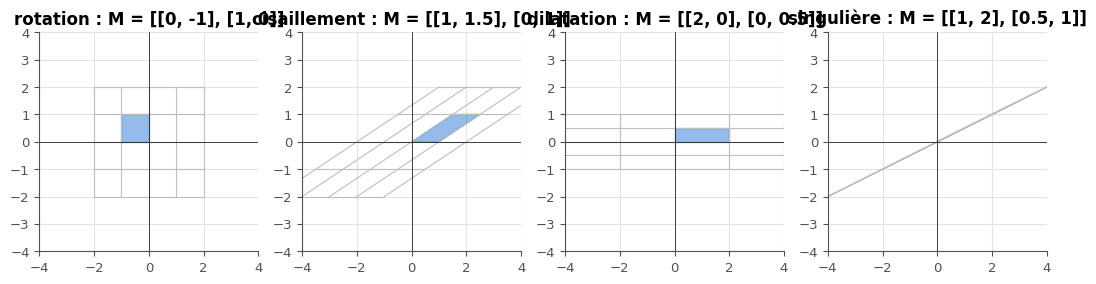

In [43]:
from matplotlib.patches import Polygon


def draw_transform(ax, M):
    """In ax, the image by M of the grid lines x, y in {-2, ..., 2} (grey) and of the unit square (a Polygon)."""
    M = np.asarray(M, dtype=float)
    for c in range(-2, 3):
        for start, end in (((c, -2), (c, 2)), ((-2, c), (2, c))):    # a vertical, then a horizontal line
            ends = np.array([start, end], dtype=float) @ M.T            # each row x becomes M x
            ax.plot(ends[:, 0], ends[:, 1], color="0.75", lw=0.8)
    square = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float) @ M.T
    ax.add_patch(Polygon(square, closed=True, facecolor="C0", alpha=0.5, edgecolor="C0"))
    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)


matrices_33 = [("rotation", [[0, -1], [1, 0]]), ("cisaillement", [[1, 1.5], [0, 1]]),
               ("dilatation", [[2, 0], [0, 0.5]]), ("singulière", [[1, 2], [0.5, 1]])]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, M) in zip(axes, matrices_33):
    draw_transform(ax, M)
    ax.set(title=f"{name} : M = {M}", aspect="equal", xlim=(-4, 4), ylim=(-4, 4))
plt.show()

**Vérifications automatiques** (sur les mêmes matrices, dans des axes neufs).

In [44]:
with checked("M09a.33 vérifications"):
    from matplotlib.patches import Polygon
    problems = []
    for M_t in ([[0, -1], [1, 0]], [[1, 1.5], [0, 1]], [[2, 0], [0, 0.5]], [[1, 2], [0.5, 1]]):
        fig_t, ax_t = plt.subplots()
        try:
            created = drawn(draw_transform, ax_t, M_t)
        except NotImplementedError:
            plt.close(fig_t)
            raise
        polygons = [patch for patch in ax_t.patches if isinstance(patch, Polygon)]
        lines_t = [line for line in ax_t.get_lines() if len(line.get_xdata()) > 1]
        plt.close(fig_t)
        if created:
            problems.append("draw_transform ouvre sa propre figure : dessine dans l'axe reçu")
            break
        if len(lines_t) < 10:
            problems.append(f"pour M = {M_t}, {len(lines_t)} lignes seulement : trace l'image des lignes de la grille "
                            "(au moins 5 verticales et 5 horizontales)")
            break
        if not polygons:
            problems.append("aucun polygone : trace l'image du carré unité avec matplotlib.patches.Polygon")
            break
        corners = np.asarray(polygons[0].get_xy(), dtype=float)[:4]
        expected = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float) @ np.array(M_t, dtype=float).T
        if corners.shape != (4, 2) or not np.allclose(corners, expected, atol=1e-9):
            problems.append(f"pour M = {M_t}, les sommets du polygone ne sont pas les images de (0, 0), (1, 0), "
                            "(1, 1), (0, 1), dans cet ordre (l'image d'un point x est M x)")
            break
        image_lines = np.concatenate([np.column_stack([line.get_xdata(), line.get_ydata()]) for line in lines_t])
        if not np.all(np.isfinite(image_lines)):
            problems.append("des points non finis dans les lignes tracées")
            break
    if problems:
        print("❌ Ex M09a.33 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M09a.33 : l'image de la grille et du carré unité est juste, pour quatre matrices.")

✅ Ex M09a.33 : l'image de la grille et du carré unité est juste, pour quatre matrices.


💡 Les colonnes de $\mathbf{M}$ sont les images de $\mathbf{e}_1$ et $\mathbf{e}_2$ : la rotation envoie $\mathbf{e}_1$ sur $(0, 1)$ et $\mathbf{e}_2$ sur $(-1, 0)$ ; le cisaillement garde $\mathbf{e}_1$ et penche $\mathbf{e}_2$ en $(1{,}5 ;\ 1)$ ; la dilatation étire l'axe des $x$ par 2 et écrase celui des $y$ par 2. La matrice singulière a deux colonnes proportionnelles, $(1 ;\ 0{,}5)$ et $(2, 1)$ : tout le plan est envoyé sur une droite, et le carré unité devient un segment (un parallélogramme aplati). Aucune matrice ne peut défaire cela : c'est pourquoi elle n'a pas d'inverse. La rotation d'un quart de tour dans l'autre sens, $\begin{pmatrix} 0 & 1 \\ -1 & 0 \end{pmatrix}$, défait la première : c'est son inverse, et aussi sa transposée.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §3, §4 et §6. Trois erreurs à trouver, un test de propriété, puis un grand système résolu vite et bien.

### Ex M09a.34 — Chasse à l'erreur : `*` au lieu de `@`, une transposée oubliée, un pivot nul 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur les produits, les formes et le pivot de Gauss, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §3, §4 et §6 · **Parcours :** C

Un collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle doit calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
A = np.array([[1.0, 2.0], [3.0, -1.0]])
B = np.array([[0.0, 1.0], [2.0, 2.0]])
X = np.array([[1.0, 0.0, 2.0], [-1.0, 1.0, 1.0]])      # 2 examples, 3 features
w = np.array([1.0, -2.0, 0.5])                           # weights of a linear model
P = A * B                                    # (A) the matrix product AB: its entry (2, 1), P[1, 0]
S = A + A.T                                  # (B) a symmetric matrix: S[0, 1]
y = X @ w + 1.0                              # (C) the predictions X w + 1 for the 2 examples: y[1]
G = X @ X.T                                  # (D) the 3 × 3 matrix XᵀX (one row per feature): G[0, 1]
M = np.array([[0.0, 2.0, 4.0], [1.0, 1.0, 3.0]])         # the augmented matrix of 2y = 4, x + y = 3
M[1] = M[1] - M[1, 0] / M[0, 0] * M[0]       # (E) an echelon form of M, x eliminated below the first pivot: M[1, 2]
R = np.diag(1 / np.array([2.0, 4.0])) @ A    # (F) D⁻¹A with D = diag(2, 4): row 1 halved, row 2 quartered: R[1, 0]
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 4 décimales).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? La ligne (D) s'exécute sans erreur : quelle est la forme de son résultat, et pourquoi Python ne signale-t-il rien ?

In [45]:
answer_M09a_34a = "ADE"
A = np.array([[1.0, 2.0], [3.0, -1.0]])
B = np.array([[0.0, 1.0], [2.0, 2.0]])
X = np.array([[1.0, 0.0, 2.0], [-1.0, 1.0, 1.0]])
w = np.array([1.0, -2.0, 0.5])
P = A @ B                                    # (A) the matrix product, not the Hadamard product
S = A + A.T                                  # (B) correct
y = X @ w + 1.0                              # (C) correct
G = X.T @ X                                  # (D) XᵀX, of shape (3, 3): X @ X.T is the (2, 2) matrix of the examples
M = np.array([[1.0, 1.0, 3.0], [0.0, 2.0, 4.0]])         # (E) swap the rows first: the pivot 0 cannot be used
M[1] = M[1] - M[1, 0] / M[0, 0] * M[0]
R = np.diag(1 / np.array([2.0, 4.0])) @ A    # (F) correct
answer_M09a_34b = [float(P[1, 0]), float(S[0, 1]), float(y[1]), float(G[0, 1]), float(M[1, 2]), float(R[1, 0])]
print(answer_M09a_34a, answer_M09a_34b)

ADE [-2.0, 5.0, -1.5, -1.0, 4.0, 0.75]


In [46]:
wbm.record("M09a.34a", "ADE",
           mistakes={"il manque une ligne fautive : refais à la main chaque produit de deux matrices": "DE",
                     "il manque une ligne fautive : écris la forme de chaque résultat": "AE",
                     "il manque une ligne fautive : refais à la main chaque étape du pivot de Gauss": "AD",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABDE", "ACDE", "ADEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais à la main chaque produit de deux matrices": {"BDE", "CDE", "DEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : écris la forme de chaque résultat": {"ABE", "ACE", "AEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais à la main chaque étape du pivot de Gauss": {"ABD", "ACD", "ADF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "D", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "C", "F", "AB", "AC", "AF", "BC", "BD", "BE", "BF", "CD", "CE", "CF", "DF", "EF", "ABC", "ABF", "ACF", "BCD", "BCE", "BCF", "BDF", "BEF", "CDF", "CEF", "ABCD", "ABCE", "ABCF", "ABDF", "ABEF", "ACDF", "ACEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDF", "ABCEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABDEF", "ACDEF", "ABCDEF"}})
VALUES_34 = [-2.0, 5.0, -1.5, -1.0, 4.0, 0.75]
wbm.record("M09a.34b", VALUES_34, decimals=4,
           mistakes={"(A) : le produit matriciel est @ ; * multiplie élément par élément": [6.0] + VALUES_34[1:],
                      "(D) : XᵀX a une ligne et une colonne par feature ; X @ X.T en a une par exemple":
                          VALUES_34[:3] + [1.0] + VALUES_34[4:]})

WBM_ANSWER {"hash": "b3d39f5e03eb462398657df24e97cd21758652ecbf35156d1cc407bfdc9a5b6c", "id": "M09a.34a", "kind": "str", "mistakes": {"05e1186630496bdaa27a4d950b79d0b2604d51324c41331ce3b1f924c1c92ed9": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "080f0f7e7cf0c67ad055f8dd53c623faf3c25a252edaaba198c161e47e56269d": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "095f782c8bbfb517851ae395c5168429ba87610b142a50acd8f7ec6be1cbfc3e": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0ba0972fcf7687fbd04229cd941dab1dd2f2c299aee343798c2f987578bbcc41": "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple", "0dbca4cfc6c2101b1b0f83befd63df5e4e97fff1f8fdb420cfbe515560fa1f85": "il manque des lignes fautives, et des lignes que tu cites sont correcte

💡 (A) `A * B` est le produit de Hadamard : son élément $(2, 1)$ vaut $3 \times 2 = 6$, alors que celui de $\mathbf{A}\mathbf{B}$ vaut $3 \times 0 + (-1) \times 2 = -2$ ; il faut `A @ B`. (B) est juste : $2 + 3 = 5$. (C) est juste : $-1 - 2 + 0{,}5 + 1 = -1{,}5$. (D) `X @ X.T` est de forme $(2, 2)$ : c'est la matrice des produits scalaires des **exemples**, et son élément $(1, 2)$ existe, d'où l'absence d'erreur ; $\mathbf{X}^\top\mathbf{X}$, de forme $(3, 3)$, s'écrit `X.T @ X`, et son élément $(1, 2)$ est le produit scalaire des colonnes 1 et 2, $1 \times 0 + (-1) \times 1 = -1$. (E) Le pivot $M_{11}$ vaut 0 : la ligne divise par zéro (`inf` et `nan`) ; il faut d'abord échanger les deux lignes, et l'on trouve $4$. (F) est juste : $\frac{3}{4} = 0{,}75$.

### Ex M09a.35 — Tester une propriété : un pytest pour (AB)ᵀ = BᵀAᵀ sur des matrices aléatoires 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test fondé sur une propriété, vérifiée sur des matrices aléatoires de formes variées, et voir ce qu'un tel test ne peut pas attraper.  
**Prérequis :** fiche §4 ; Ex M09a.15 et M09a.25 · **Parcours :** C

Un test peut comparer une fonction à un **oracle** (une fonction de confiance, comme `@` dans les tests de `mymath`), ou vérifier une **propriété** que le résultat doit avoir : ici, $(\mathbf{A}\mathbf{B})^\top = \mathbf{B}^\top\mathbf{A}^\top$ (M09a.15), pour des matrices tirées au hasard. Écris :
- `check_transpose_of_product(matmul, transpose, seed, trials=10)` : avec `rng = np.random.default_rng(seed)`, répète `trials` fois : tire trois dimensions $n, p, m$ entre 1 et 5 (`rng.integers(1, 6, size=3)`), deux matrices $\mathbf{A}$ $(n, p)$ et $\mathbf{B}$ $(p, m)$ de loi normale, et vérifie par `assert` (avec un message) que `transpose(matmul(A, B))` et `matmul(transpose(B), transpose(A))` ont la même forme et sont égales à $10^{-12}$ près (`np.allclose`) ;
- `test_transpose_of_product()` : le test au format pytest, sans argument, qui appelle `check_transpose_of_product` avec les fonctions de **ta** librairie (`mymath.matrices.matmul` et `mymath.matrices.transpose`) et une graine fixe.

La cellule fournie définit deux copies fausses : une transposée par `reshape`, et un produit qui rend le produit de Hadamard quand les deux matrices ont la même forme. La vérification lance ton test sur les bonnes fonctions (la référence) et sur chaque copie fausse, pour 20 graines.

Dans ta copie : pour quelles formes la transposée par `reshape` rend-elle le bon résultat, et pourquoi un test qui ne tirerait que ces formes la laisserait-il passer ? La copie au produit de Hadamard passe ton test : pourquoi la propriété est-elle vraie pour elle aussi ? Que faut-il ajouter pour l'attraper ?

In [47]:
def transpose_reshape(A):          # a copy with a bug
    A = np.asarray(A, dtype=float)
    return A.reshape(A.shape[1], A.shape[0])


def matmul_square_hadamard(A, B):    # a copy with another bug
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    if A.shape == B.shape:
        return A * B
    return A @ B

In [48]:
def check_transpose_of_product(matmul, transpose, seed, trials=10):
    """Assert (AB)ᵀ = BᵀAᵀ on `trials` pairs of random matrices of random shapes, drawn with default_rng(seed)."""
    rng = np.random.default_rng(seed)
    for _ in range(trials):
        n, p, m = rng.integers(1, 6, size=3)
        A, B = rng.normal(size=(n, p)), rng.normal(size=(p, m))
        left = np.asarray(transpose(matmul(A, B)), dtype=float)
        right = np.asarray(matmul(transpose(B), transpose(A)), dtype=float)
        assert left.shape == right.shape and np.allclose(left, right, rtol=0, atol=1e-12), (
            f"expected (AB)ᵀ = BᵀAᵀ for A of shape {A.shape} and B of shape {B.shape}, got shapes {left.shape} and "
            f"{right.shape}")


def test_transpose_of_product():
    """The pytest test: check_transpose_of_product on your matmul and transpose, with a fixed seed."""
    check_transpose_of_product(mymath.matrices.matmul, mymath.matrices.transpose, seed=35)


test_transpose_of_product()
print("the property holds for the reference")

the property holds for the reference


In [49]:
with checked("M09a.35 vérifications"):
    problems = []
    ref_35 = wbm.load_mymath("ref").matrices

    def outcome(matmul_t, transpose_t, seed):
        """None if check_transpose_of_product passes, else the message of its AssertionError."""
        try:
            check_transpose_of_product(matmul_t, transpose_t, seed)
        except AssertionError as exc:
            return str(exc)
        return None

    passed = sum(outcome(ref_35.matmul, ref_35.transpose, seed) is None for seed in range(20))
    caught_reshape = [outcome(ref_35.matmul, transpose_reshape, seed) for seed in range(20)]
    caught_hadamard = [outcome(matmul_square_hadamard, ref_35.transpose, seed) for seed in range(20)]
    print(f"la bonne paire passe ton test {passed} fois sur 20 ; la transposée par reshape est attrapée "
          f"{sum(m is not None for m in caught_reshape)} fois sur 20 ; le produit de Hadamard pour des matrices carrées, "
          f"{sum(m is not None for m in caught_hadamard)} fois sur 20")
    if passed < 20:
        problems.append("ton test échoue sur les bonnes fonctions : compare avec np.allclose (des flottants), pas avec ==")
    if sum(m is not None for m in caught_reshape) < 20:
        problems.append("ton test laisse passer la transposée par reshape : tire des matrices de formes aléatoires, "
                        "avec au moins deux lignes et deux colonnes")
    if not problems and any(not (m or "").strip() for m in caught_reshape):
        problems.append("ajoute un message à ton assert (assert condition, message)")
    if not problems:
        try:
            test_transpose_of_product()
        except AssertionError as exc:
            problems.append(f"test_transpose_of_product échoue sur ta librairie : {exc}")
    if problems:
        print("❌ Ex M09a.35 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M09a.35 : ton test passe sur les bonnes fonctions et attrape la transposée fausse.")

la bonne paire passe ton test 20 fois sur 20 ; la transposée par reshape est attrapée 20 fois sur 20 ; le produit de Hadamard pour des matrices carrées, 0 fois sur 20
✅ Ex M09a.35 : ton test passe sur les bonnes fonctions et attrape la transposée fausse.


💡 La transposée par `reshape` garde l'ordre des nombres ligne par ligne : elle rend la bonne forme, mais de mauvais nombres, sauf pour une seule ligne ou une seule colonne, où les deux coïncident. Un test qui ne tirerait que des vecteurs la laisserait passer ; des formes aléatoires, avec au moins deux lignes et deux colonnes, la démasquent (une matrice carrée suffit : `reshape` la rend inchangée). Le produit de Hadamard de deux matrices carrées vérifie la propriété, car $(\mathbf{A} \odot \mathbf{B})^\top = \mathbf{A}^\top \odot \mathbf{B}^\top = \mathbf{B}^\top \odot \mathbf{A}^\top$ : un test de propriété ne vérifie qu'une conséquence de la bonne réponse, et une fonction fausse peut la partager. Pour l'attraper, il faut aussi comparer à un oracle (`@`) ou à quelques produits calculés à la main, comme le font les tests de `mymath`.

### Ex M09a.36 — Défi : un système 500 × 500 résolu par ton `solve`, à 1e−8 près de NumPy, en moins d'une seconde 🏆 ★★★ ⏱️ 30 min
**Objectif :** rendre ta fonction `solve` à la fois précise et rapide sur un grand système, en vectorisant l'élimination.  
**Prérequis :** fiche §6 ; Ex M09a.27 et M09a.32 · **Parcours :** C

Ta fonction `solve` (M09a.27) passe ses tests sur de petits systèmes. **L'objectif** : qu'elle résolve trois systèmes $500 \times 500$ (deux tirés au hasard, un troisième dont la diagonale est minuscule) à $10^{-8}$ près de `np.linalg.solve`, en **moins d'une seconde** chacun, sans `np.linalg` ni `@` (la règle de `matrices.py`).

Une élimination qui traite les nombres un par un (une boucle Python sur les lignes sous le pivot, puis une sur les colonnes) fait de l'ordre de $\frac{2}{3}n^3 \approx 8 \times 10^7$ opérations Python pour $n = 500$ : plusieurs secondes, souvent bien plus. Pistes : traiter chaque ligne d'un coup (une opération NumPy sur une ligne entière), ou mieux toutes les lignes sous le pivot d'un coup (une opération sur le bloc `M[k + 1:]`, avec le broadcasting d'une colonne de multiplicateurs), et garder le pivot partiel. La vérification s'arrête au premier système trop lent.

La vérification essaie ta fonction sur les trois systèmes ; une dernière cellule enregistre si l'objectif est atteint sur les trois.

Dans ta copie : combien de temps prenait ta première version, et combien la version finale ? Quelle opération as-tu vectorisée ? Pourquoi le troisième système échoue-t-il sans pivot partiel ?

In [50]:
print("the reference solve (mymath_ref/matrices.py) eliminates below each pivot in one NumPy operation:")
print("    factors = M[k + 1:, k] / M[k, k]")
print("    M[k + 1:] = M[k + 1:] - factors[:, None] * M[k]")

the reference solve (mymath_ref/matrices.py) eliminates below each pivot in one NumPy operation:
    factors = M[k + 1:, k] / M[k, k]
    M[k + 1:] = M[k + 1:] - factors[:, None] * M[k]


In [51]:
wbm.record("M09a.36", True,
           mistakes={"l'objectif n'est pas atteint sur les trois systèmes : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "86db6a5bdc50099be39983d3b57cf328757dafcdae1169d0d8e92a9216a3a230", "id": "M09a.36", "kind": "bool", "mistakes": {"4cec742059c9fa2cbc98971e4491f4f0211fbcc5837da176e6d5361c9b24d0c2": "l'objectif n'est pas atteint sur les trois systèmes : la cellule du défi dit pourquoi"}}
📝 Ex M09a.36 : réponse enregistrée (bool).


In [52]:
with checked("M09a.36 défi"):
    problems, worst_error, slowest, ok_36 = [], 0.0, 0.0, False
    for seed_t, kind_t in [(36, "random"), (37, "random"), (38, "needs-pivoting")]:
        rng_t = np.random.default_rng(seed_t)
        A_t = rng_t.normal(size=(500, 500))
        if kind_t == "needs-pivoting":
            A_t[np.arange(500), np.arange(500)] = 1e-14          # tiny diagonal: elimination without swaps fails
        b_t = rng_t.normal(size=500)
        exact_t = np.linalg.solve(A_t, b_t)
        start_t = time.perf_counter()
        try:
            x_t = mymath.matrices.solve(A_t.copy(), b_t.copy())
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"solve lève {type(exc).__name__} ({exc})")
            break
        seconds_t = time.perf_counter() - start_t
        slowest = max(slowest, seconds_t)
        x_t = np.asarray(x_t, dtype=float)
        if x_t.shape != (500,):
            problems.append(f"solve rend la forme {x_t.shape}, pas (500,)")
            break
        worst_error = max(worst_error, float(np.max(np.abs(x_t - exact_t))))
        if seconds_t > 1:
            break                                                # too slow: the other systems would be too
    if not problems:
        print(f"plus grande erreur : {worst_error:.1e} · temps le plus long : {slowest:.3f} s")
        if worst_error > 1e-8:
            problems.append("l'erreur dépasse 1e-8 : vérifie le pivot partiel (le troisième système a une diagonale "
                            "minuscule)")
        if slowest > 1:
            problems.append(f"plus d'une seconde ({slowest:.1f} s) : remplace les boucles sur les éléments par des "
                            "opérations NumPy sur des lignes entières, ou sur tout le bloc M[k + 1:] d'un coup")
    if problems:
        print("❌ Ex M09a.36 : " + " ; ".join(problems) + ".")
    else:
        ok_36 = True
        print("✅ Ex M09a.36 : défi réussi : trois systèmes 500 × 500, à 1e-8 près, en moins d'une seconde chacun.")

plus grande erreur : 1.7e-12 · temps le plus long : 0.193 s
✅ Ex M09a.36 : défi réussi : trois systèmes 500 × 500, à 1e-8 près, en moins d'une seconde chacun.


💡 La boucle sur les lignes sous le pivot se remplace par une seule opération sur le bloc : la colonne des multiplicateurs `M[k + 1:, k] / M[k, k]`, de forme $(n - k - 1,)$, devient une colonne par `[:, None]`, et le broadcasting la multiplie par la ligne du pivot. Il reste une seule boucle Python, sur les $n$ colonnes : le système $500 \times 500$ se résout en un à deux dixièmes de seconde. Une boucle sur les lignes, chaque ligne traitée d'un coup, passe aussi ; une boucle sur chaque nombre, non : de l'ordre de $10^8$ opérations Python. Le troisième système a une diagonale de $10^{-14}$ : sans échange de lignes, chaque élimination divise par ces pivots minuscules, et l'erreur explose (M09a.32).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu prévoir la forme d'un produit, et calculer un produit matrice-vecteur sous ses deux lectures ?
2. Sais-tu calculer un produit matriciel, son coût, et écrire une couche $\mathbf{Z} = \mathbf{X}\mathbf{W} + \mathbf{b}$ ?
3. Sais-tu appliquer les règles de la transposée, et calculer $\mathbf{X}^\top\mathbf{X}$ ?
4. Sais-tu résoudre un système par le pivot de Gauss, et décrire toutes ses solutions ?
5. Sais-tu calculer une inverse et un rang, et dire quand une matrice est singulière ?

**La suite** : le chapitre 9 de workbookIA (overfitting et régularisation, avec des régressions écrites en produits matriciels), puis M09b, les moindres carrés.